<div class="alert alert-block alert-info">
<center> <h1> Data Mining - A2Z Insurance Project </h1> </center> <br>

**Index** <br>
* [Imports and Function Definitions](#import)
* [File Load](#fileload)
* [Data Exploration](#exploration)
* [Inconsistencies/Incoherences and Duplicates](#inconsistent)
* [Data Imputation](#imputation)
    * [1. Median and Mode](#medianmode)
    * [2. KNN Imputation with weights="uniform" and Mode](#uknnmode)
    * [3. KNN Imputation with weights="distance" and Mode](#dknnmode)
    * [4. IterativeImputer using Linear and Logistic Regressions as Estimators](#iterativell)
* [Outlier Removal](#outlieremoval)
    * [1. Manual](#manual)
    * [2. IQR](#iqr)
    * [3. Manual and IQR](#manualiqr)
    * [4. Z-Score](#zscore)
    * [5. DBSCAN](#dbscan)
    * [6. Isolation Forest](#isolation)
* [Analysis of the Dataset after Outlier Detection and Data Imputation](#afteroutlierimputation)
* [Feature Creation](#creation)
* [Feature Selection](#selection)
    * [1. Filter Methods](#filter)
        * [1.1 Variance of the Metric Features](#variance)
        * [1.2 Association Measures](#association)
* [Feature Scaling](#scaling)
    * [1. MinMax Scaler](#minmax)
    * [2. Standard Scaler](#standard)
    * [3. Robust Scaler](#robust)
* [Detection of the Remaining Outliers in our Dataset (using DBSCAN)](#remainingoutliers)
* [Clustering by Perspectives](#clustering) 
    * [1. Demographic Perspective](#demographic)
        * [1.1 K-prototypes](#kprototypes)
    * [2. Behavioral Perspective](#behavioral)
        * [2.1 K-means](#kmeans)
        * [2.2 K-means and Hierarchical Clustering](#hkm)
        * [2.3 Gaussian Mixture Model](#gmm)
        * [2.4 Self-organizing Map and K-means](#ksom)
        * [2.5 Self-organizing Map and Hierarchical Clustering](#hcsom)
* [Merging the Perspectives](#merge)
* [Cluster Visualization using t-SNE](#tsne)
* [Assess Feature Importance and Classify Outliers](#importanceoutliers)
    * [1. Decision Tree Classifier](#dt)
    * [2. K-nearest Neighbors Classifier](#knn)

<a class="anchor" id="import">
    
# Imports and Function Definitions
    
</a>

In [179]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import graphviz
import sompy
from sompy.visualization.mapview import View2D
from sompy.visualization.bmuhits import BmuHitsView
from sompy.visualization.hitmap import HitMapView
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import KNNImputer,IterativeImputer
from sklearn.preprocessing import OneHotEncoder,MinMaxScaler, RobustScaler, StandardScaler
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import NearestNeighbors,KNeighborsClassifier
from sklearn.cluster import DBSCAN,KMeans,AgglomerativeClustering
from sklearn.linear_model import LinearRegression,LogisticRegression
from sklearn.metrics import silhouette_score
from sklearn.mixture import GaussianMixture
from sklearn.manifold import TSNE
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier,export_graphviz
from math import ceil
from pandas_profiling import ProfileReport
from kmodes.kprototypes import KPrototypes
from scipy.cluster.hierarchy import dendrogram

import warnings
warnings.filterwarnings('ignore')

In [180]:
from matplotlib.patches import RegularPolygon, Ellipse
from mpl_toolkits.axes_grid1 import make_axes_locatable
from matplotlib import cm, colorbar
from matplotlib import colors as mpl_colors

from matplotlib.lines import Line2D
from matplotlib import __version__ as mplver

In [181]:
def draw_histogram(nrows, ncolumns, figsize, df, features, title):
    #all Numeric Variables' Histograms in one figure
    sns.set()

    #prepare figure. Create individual axes where each histogram will be placed
    fig, axes = plt.subplots(nrows, ncolumns, figsize=figsize)

    #plot data
    #iterate across axes objects and associate each histogram:
    for ax, feat in zip(axes.flatten(), features):
        ax.hist(df[feat])
        ax.set_title(feat, y=-0.13)

    #add a centered title to the figure:
    plt.suptitle(title)

    plt.show()

In [182]:
def draw_boxplot(nrows, ncolumns, figsize, df, features, title):
    #all Numeric Variables' Box Plots in one figure
    sns.set()

    #prepare figure. Create individual axes where each box plot will be placed
    fig, axes = plt.subplots(nrows, ncolumns, figsize=figsize)

    #plot data
    #iterate across axes objects and associate each box plot:
    for ax, feat in zip(axes.flatten(), features): 
        sns.boxplot(x=df[feat], ax=ax)

    #add a centered title to the figure:
    plt.suptitle(title)

    plt.show()

In [183]:
def draw_parwise_relationship(df, features, title):
    #pairwise Relationship of Numerical Variables
    sns.set()

    #setting pairplot
    sns.pairplot(df[features], diag_kind="hist")

    #layout
    plt.subplots_adjust(top=0.95)
    plt.suptitle(title, fontsize=20)

    plt.show()

In [184]:
def draw_pretty_correlation(df, features, title):
    #prepare figure
    fig = plt.figure(figsize=(10, 8))

    #obtain correlation matrix (using spearman)
    corr = np.round(df[features].corr(method="spearman"), decimals=2)

    #build annotation matrix (values above |0.5| will appear annotated in the plot)
    mask_annot = np.absolute(corr.values) >= 0.5
    annot = np.where(mask_annot, corr.values, np.full(corr.shape,"")) 

    #plot heatmap of the correlation matrix
    sns.heatmap(data=corr, annot=annot, cmap=sns.diverging_palette(220, 10, as_cmap=True), 
                fmt='s', vmin=-1, vmax=1, center=0, square=True, linewidths=.5)

    #layout
    fig.subplots_adjust(top=0.95)
    fig.suptitle(title, fontsize=20)

    plt.show()

<a class="anchor" id="fileload">

# File Load
</a>

In [185]:
df = pd.read_sas('a2z_insurance.sas7bdat')
df.head()

,CustID,FirstPolYear,BirthYear,EducDeg,MonthSal,GeoLivArea,Children,CustMonVal,ClaimsRate,PremMotor,PremHousehold,PremHealth,PremLife,PremWork
0,1.0,1985.0,1982.0,b'2 - High School',2177.0,1.0,1.0,380.97,0.39,375.85,79.45,146.36,47.01,16.89
1,2.0,1981.0,1995.0,b'2 - High School',677.0,4.0,1.0,-131.13,1.12,77.46,416.20,116.69,194.48,106.13
2,3.0,1991.0,1970.0,b'1 - Basic',2277.0,3.0,0.0,504.67,0.28,206.15,224.50,124.58,86.35,99.02
3,4.0,1990.0,1981.0,b'3 - BSc/MSc',1099.0,4.0,1.0,-16.99,0.99,182.48,43.35,311.17,35.34,28.34
4,5.0,1986.0,1973.0,b'3 - BSc/MSc',1763.0,4.0,1.0,35.23,0.90,338.62,47.80,182.59,18.78,41.45


In [186]:
#security copy of the dataset read
df_original=df.copy() 

<a class="anchor" id="exploration">
    
#  Data Exploration
</a>

In [187]:
#generating a profile report to better explore the data
ProfileReport(  
    df,    
    title='A2Z Insurance Data',
    correlations={
        "pearson": {"calculate": True},
        "spearman": {"calculate": True},
        "kendall": {"calculate": True},
        "phi_k": {"calculate": True},
        "cramers": {"calculate": True},
    },                 
)

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

In [188]:
df.info()   #all columns except EducDeg are of float type

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10296 entries, 0 to 10295
Data columns (total 14 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   CustID         10296 non-null  float64
 1   FirstPolYear   10266 non-null  float64
 2   BirthYear      10279 non-null  float64
 3   EducDeg        10279 non-null  object 
 4   MonthSal       10260 non-null  float64
 5   GeoLivArea     10295 non-null  float64
 6   Children       10275 non-null  float64
 7   CustMonVal     10296 non-null  float64
 8   ClaimsRate     10296 non-null  float64
 9   PremMotor      10262 non-null  float64
 10  PremHousehold  10296 non-null  float64
 11  PremHealth     10253 non-null  float64
 12  PremLife       10192 non-null  float64
 13  PremWork       10210 non-null  float64
dtypes: float64(13), object(1)
memory usage: 1.1+ MB


In [189]:
df['FirstPolYear'].unique() #no decimal values

array([ 1985.,  1981.,  1991.,  1990.,  1986.,  1979.,  1988.,  1976.,
        1983.,  1977.,  1998.,  1974.,  1978.,  1995.,  1980.,  1984.,
        1989.,  1987.,  1982.,  1994.,  1993.,  1992.,  1997.,  1996.,
        1975.,    nan, 53784.])

In [190]:
df['BirthYear'].unique()   #no decimal values

array([1982., 1995., 1970., 1981., 1973., 1956., 1943., 1974., 1978.,
       1948., 1945., 1958., 1949., 2000., 1975., 1979., 1989., 1962.,
       1986., 1961., 1952., 1944., 1937., 1942., 1972., 1953., 1966.,
       1955., 1941., 1938., 1968., 1990., 1984., 1980., 1946., 1965.,
       1957., 1967., 1977., 1951., 1985., 1959., 1988., 1983., 1939.,
       1964., 1950., 1960., 1976., 1971., 1954., 1969., 1994., 1992.,
       1997., 1963., 1991., 1999., 1993., 1947., 1987., 1996., 1940.,
       1935., 1936.,   nan, 1998., 2001., 1028.])

In [191]:
df["CustID"] = df["CustID"].astype("int64")  #cannot change the type of the other ones because they have missing values

In [192]:
df.isna().sum()   #we can see that we have missing values in metric and non-metric features

CustID             0
FirstPolYear      30
BirthYear         17
EducDeg           17
MonthSal          36
GeoLivArea         1
Children          21
CustMonVal         0
ClaimsRate         0
PremMotor         34
PremHousehold      0
PremHealth        43
PremLife         104
PremWork          86
dtype: int64

In [193]:
#set customer id as index since it is unique and non-null
df.set_index('CustID', inplace=True)

In [194]:
#we can see the presence of outliers (difference between mean and median and extreme values in min/max)
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
FirstPolYear,10266.0,NaN,NaN,NaN,1991.062634,511.267913,1974.0,1980.0,1986.0,1992.0,53784.0
BirthYear,10279.0,NaN,NaN,NaN,1968.007783,19.709476,1028.0,1953.0,1968.0,1983.0,2001.0
EducDeg,10279,4,b'3 - BSc/MSc',4799,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MonthSal,10260.0,NaN,NaN,NaN,2506.667057,1157.449634,333.0,1706.0,2501.5,3290.25,55215.0
GeoLivArea,10295.0,NaN,NaN,NaN,2.709859,1.266291,1.0,1.0,3.0,4.0,4.0
Children,10275.0,NaN,NaN,NaN,0.706764,0.455268,0.0,0.0,1.0,1.0,1.0
CustMonVal,10296.0,NaN,NaN,NaN,177.892605,1945.811505,-165680.42,-9.44,186.87,399.7775,11875.89
ClaimsRate,10296.0,NaN,NaN,NaN,0.742772,2.916964,0.0,0.39,0.72,0.98,256.2
PremMotor,10262.0,NaN,NaN,NaN,300.470252,211.914997,-4.11,190.59,298.61,408.3,11604.42
PremHousehold,10296.0,NaN,NaN,NaN,210.431192,352.595984,-75.0,49.45,132.8,290.05,25048.8


In [195]:
df[df.duplicated()]  #duplicate rows

,FirstPolYear,BirthYear,EducDeg,MonthSal,GeoLivArea,Children,CustMonVal,ClaimsRate,PremMotor,PremHousehold,PremHealth,PremLife,PremWork
CustID,,,,,,,,,,,,,
8014,1987.0,1987.0,b'2 - High School',1912.0,4.0,1.0,290.61,0.58,202.37,177.25,306.39,63.90,-0.11
8122,1977.0,1974.0,b'2 - High School',2204.0,4.0,1.0,-22.11,1.00,214.93,88.90,266.94,39.23,42.12
9554,1986.0,1952.0,b'2 - High School',3900.0,4.0,0.0,-119.35,1.10,163.03,481.75,224.82,94.35,18.56


In [196]:
#define the metric and non-metric features
non_metric_features = ["EducDeg", "GeoLivArea", "Children"]
metric_features = df.columns.drop(non_metric_features).to_list()

<a class="anchor" id="inconsistent">

# Inconsistencies/Incoherences and Duplicates
</a>

In [197]:
df.drop_duplicates(inplace=True)  #duplicate rows (very difficult for different people to have these exact same results on all variables)

In [198]:
df['FirstPolYear'].replace(53784,np.nan,inplace=True)

In [199]:
(df['FirstPolYear']<df['BirthYear']).sum()

1997

In [200]:
df[df['BirthYear']==2001]  #people with 15 years old with big salaries

,FirstPolYear,BirthYear,EducDeg,MonthSal,GeoLivArea,Children,CustMonVal,ClaimsRate,PremMotor,PremHousehold,PremHealth,PremLife,PremWork
CustID,,,,,,,,,,,,,
660,1991.0,2001.0,b'1 - Basic',1284.0,4.0,1.0,243.50,0.81,46.23,1079.65,72.68,252.27,-10.00
690,1997.0,2001.0,b'1 - Basic',1180.0,3.0,1.0,436.10,0.48,54.90,406.20,65.79,112.02,256.05
866,1979.0,2001.0,b'1 - Basic',562.0,1.0,1.0,1113.78,0.11,40.34,847.95,94.24,178.70,112.13
1437,1989.0,2001.0,b'1 - Basic',823.0,4.0,0.0,281.28,0.60,129.58,177.80,58.01,176.70,218.15
2580,1986.0,2001.0,b'1 - Basic',1006.0,4.0,0.0,267.95,0.67,48.23,396.75,291.50,127.58,24.45
3147,1994.0,2001.0,b'1 - Basic',372.0,4.0,1.0,488.76,0.36,60.68,270.60,177.59,182.48,107.13
4466,1978.0,2001.0,b'1 - Basic',958.0,4.0,0.0,-204.59,1.11,28.56,1359.15,68.79,38.23,179.59
4484,1983.0,2001.0,b'1 - Basic',1241.0,3.0,1.0,909.17,0.13,43.34,589.55,142.47,121.80,179.48
5348,1980.0,2001.0,b'1 - Basic',1119.0,3.0,1.0,796.71,0.23,148.14,628.45,221.82,45.12,30.23


In [201]:
#we removed the feature BirthYear taking into account the inconsistencies (also explained in the report)
df.drop(columns='BirthYear',inplace=True)
metric_features.remove('BirthYear')

<a class="anchor" id="imputation">
    
# Data Imputation
</a>

In [202]:
(df['PremMotor']==0).any()  #verifying if there are any 0 values in the data for these premiums
(df['PremLife']==0).any()
(df['PremWork']==0).any()

False

In [203]:
df['PremMotor'].fillna(0,inplace=True)  #there are no 0 values in the data for these premiums which seems unreasonable considering the number of observations
df['PremLife'].fillna(0,inplace=True)  #therefore we considered the missing values to be 0
df['PremWork'].fillna(0,inplace=True)

<a class="anchor" id="medianmode">
    
### 1. Median and Mode
</a>

In [204]:
df_central = df.copy()

In [205]:
df_central.median(numeric_only=True)

FirstPolYear     1986.00
MonthSal         2502.00
GeoLivArea          3.00
Children            1.00
CustMonVal        187.03
ClaimsRate          0.72
PremMotor         298.39
PremHousehold     132.80
PremHealth        162.81
PremLife           25.45
PremWork           25.56
dtype: float64

In [206]:
modes = df_central[non_metric_features].mode().loc[0]
modes

EducDeg       b'3 - BSc/MSc'
GeoLivArea               4.0
Children                 1.0
Name: 0, dtype: object

In [207]:
df_central.fillna(df_central.median(numeric_only=True), inplace=True)
df_central.fillna(modes, inplace=True)
df_central.isna().sum()  #checking how many NaNs we still have

FirstPolYear     0
EducDeg          0
MonthSal         0
GeoLivArea       0
Children         0
CustMonVal       0
ClaimsRate       0
PremMotor        0
PremHousehold    0
PremHealth       0
PremLife         0
PremWork         0
dtype: int64

<a class="anchor" id="uknnmode">
    
### 2. KNN Imputation with weights="uniform" and Mode
</a>

In [208]:
df_neighbors = df.copy()

In [209]:
scaler=MinMaxScaler() #scaling the data
scaled_feat=scaler.fit_transform(df_neighbors[metric_features])
df_neighbors.loc[:,metric_features]=scaled_feat

In [210]:
df_uneighbors=df_neighbors.copy()

In [211]:
imputer = KNNImputer(n_neighbors=5, weights="uniform")
df_uneighbors[metric_features] = imputer.fit_transform(df_uneighbors[metric_features])
scaled_feat=scaler.inverse_transform(df_uneighbors[metric_features])   #reversing the scale
df_uneighbors.loc[:,metric_features]=scaled_feat

In [212]:
df_uneighbors.isna().sum() 

FirstPolYear      0
EducDeg          17
MonthSal          0
GeoLivArea        1
Children         21
CustMonVal        0
ClaimsRate        0
PremMotor         0
PremHousehold     0
PremHealth        0
PremLife          0
PremWork          0
dtype: int64

In [213]:
modes = df_uneighbors[non_metric_features].mode().loc[0]
df_uneighbors.fillna(modes, inplace=True)
df_uneighbors.isna().sum()  #checking how many NaNs we still have

FirstPolYear     0
EducDeg          0
MonthSal         0
GeoLivArea       0
Children         0
CustMonVal       0
ClaimsRate       0
PremMotor        0
PremHousehold    0
PremHealth       0
PremLife         0
PremWork         0
dtype: int64

<a class="anchor" id="dknnmode">
    
### 3. KNN Imputation with weights="distance" and Mode
</a>

In [214]:
df_wneighbors=df_neighbors.copy()

In [215]:
imputer = KNNImputer(n_neighbors=5, weights="distance")
df_wneighbors[metric_features] = imputer.fit_transform(df_wneighbors[metric_features])

In [216]:
scaled_feat=scaler.inverse_transform(df_wneighbors[metric_features])  #reversing the scale
df_wneighbors.loc[:,metric_features]=scaled_feat

In [217]:
df_wneighbors.isna().sum() 

FirstPolYear      0
EducDeg          17
MonthSal          0
GeoLivArea        1
Children         21
CustMonVal        0
ClaimsRate        0
PremMotor         0
PremHousehold     0
PremHealth        0
PremLife          0
PremWork          0
dtype: int64

In [218]:
modes = df_wneighbors[non_metric_features].mode().loc[0]
df_wneighbors.fillna(modes, inplace=True)
df_wneighbors.isna().sum()  #checking how many NaNs we still have

FirstPolYear     0
EducDeg          0
MonthSal         0
GeoLivArea       0
Children         0
CustMonVal       0
ClaimsRate       0
PremMotor        0
PremHousehold    0
PremHealth       0
PremLife         0
PremWork         0
dtype: int64

<a class="anchor" id="iterativell">
    
### 4. IterativeImputer using Linear and Logistic Regressions as Estimators
</a>

In [219]:
df_ll=df.copy()

In [220]:
df_ll['EducDeg']=df_ll['EducDeg'].astype(str).str.replace("'","")  #had to replace in order to use apply() afterwards

In [221]:
#here, we are only transforming this way the education feature because it has missing values and we want to impute them 
#with the iterativeimputer
#afterwards, we will use the one hot encoder
df_ll['EducDeg'].unique()
classification_education={"b1 - Basic":1,"b2 - High School":2,"b3 - BSc/MSc":3,"b4 - PhD":4,"nan":np.nan}
df_ll['EducDeg']=df_ll['EducDeg'].apply(lambda x:classification_education[x])

In [222]:
#first impute the missing values on the metric features
imp_reg = IterativeImputer(estimator=LinearRegression(),max_iter=100, random_state=10)
result = imp_reg.fit_transform(df_ll[metric_features])
df_ll[metric_features]=result

In [223]:
#second impute the missing values on the non-metric features
imp_cat = IterativeImputer(estimator=LogisticRegression(), initial_strategy='most_frequent',max_iter=100, random_state=10)
result = imp_cat.fit_transform(df_ll[non_metric_features])  
df_ll[non_metric_features]=result

In [224]:
classification_education={1:"b1 - Basic",2:"b2 - High School",3:"b3 - BSc/MSc",4:"b4 - PhD"}
df_ll['EducDeg']=df_ll['EducDeg'].apply(lambda x:classification_education[x])

In [225]:
df_ll.isna().sum()

FirstPolYear     0
EducDeg          0
MonthSal         0
GeoLivArea       0
Children         0
CustMonVal       0
ClaimsRate       0
PremMotor        0
PremHousehold    0
PremHealth       0
PremLife         0
PremWork         0
dtype: int64

<a class="anchor" id="outlieremoval">
    
# Outlier Removal    
</a>

In [226]:
#we used one hot encoder now because we need to transform it for isolation forest 
#and we will keep this feature like this for the rest of the work
oenc=OneHotEncoder(drop='first',sparse=False)        
ohc_feat = oenc.fit_transform(df_wneighbors[['EducDeg']])
ohc_feat_names = oenc.get_feature_names_out()
ohc_df = pd.DataFrame(data=ohc_feat,columns=ohc_feat_names)
ohc_df.index=df_wneighbors.index
df_wneighbors = pd.concat([df_wneighbors.drop(columns=['EducDeg']), ohc_df], axis=1)
df_wneighbors.rename(columns={"EducDeg_b'2 - High School'":'HighSchool',"EducDeg_b'3 - BSc/MSc'":'BSc/MSc',"EducDeg_b'4 - PhD'":'PhD'},inplace=True)

<a class="anchor" id="manual">

### 1. Manual 
</a>

In [227]:
filters1 = (
    (df['MonthSal']<34490)
    &
    (df['CustMonVal']<5596)
    &
    (df['CustMonVal']>-165680)
    &
    (df['ClaimsRate']<256)
    &
    (df['PremHousehold']<25048)
    &
    (df['PremHealth']<28272)
)

filters1.index=df_wneighbors.index
df_wneighbors1 = df_wneighbors[filters1]
print('Percentage of data kept after removing outliers:', np.round(df_wneighbors1.shape[0] / df.shape[0], 4))

Percentage of data kept after removing outliers: 0.9918


<a class="anchor" id="iqr">

### 2. IQR 
</a>

In [228]:
q25 = df_wneighbors.quantile(.25)
q75 = df_wneighbors.quantile(.75)
iqr = (q75 - q25)

upper_lim = q75 + 4 * iqr    
lower_lim = q25 - 4 * iqr

filters2 = []
for metric in metric_features:
    llim = lower_lim[metric]
    ulim = upper_lim[metric]
    filters2.append(df_wneighbors[metric].between(llim, ulim, inclusive='both'))

filters2 = pd.Series(np.all(filters2, 0))
filters2.index=df_wneighbors.index
df_wneighbors2 = df_wneighbors.loc[filters2]
print('Percentage of data kept after removing outliers:', np.round(df_wneighbors2.shape[0] / df.shape[0], 4))

Percentage of data kept after removing outliers: 0.9826


<a class="anchor" id="manualiqr">

### 3. Manual and IQR 
</a>

In [229]:
df_wneighbors3=df_wneighbors.copy()
df_wneighbors3 = df_wneighbors3[(filters1 | filters2)]
print('Percentage of data kept after removing outliers:', np.round(df_wneighbors3.shape[0] / df.shape[0], 4))

Percentage of data kept after removing outliers: 0.9992


<a class="anchor" id="zscore">

### 4. Z-Score
</a>

In [230]:
df_wneighbors4=df_wneighbors.copy()
df_aux=df_wneighbors.copy()
scaler=StandardScaler()  #scaling the data
scaled_feat=scaler.fit_transform(df_wneighbors[metric_features])
df_aux[metric_features]=scaled_feat
df_wneighbors4[metric_features]=scaled_feat
for metric in metric_features:
    df_wneighbors4=df_wneighbors4.loc[df_wneighbors4[metric]<3.5].loc[df_wneighbors4[metric]>-3.5]
df_out=df_aux.merge(df_wneighbors4.drop_duplicates(),on=['FirstPolYear', 'MonthSal', 'GeoLivArea', 'Children', 'CustMonVal',
       'ClaimsRate', 'PremMotor', 'PremHousehold', 'PremHealth', 'PremLife',
       'PremWork', 'HighSchool', 'BSc/MSc', 'PhD'],how='left',indicator=True)
df_out=df_out[df_out['_merge']=='left_only']
df_out.drop(columns=['_merge'],inplace=True)
inverse_feat=scaler.inverse_transform(df_wneighbors4[metric_features])    #reversing the scale
df_wneighbors4[metric_features]=inverse_feat 
print('Percentage of data kept after removing outliers:', np.round(df_wneighbors4.shape[0] / df.shape[0], 4))

Percentage of data kept after removing outliers: 0.9749


<a class="anchor" id="dbscan">

### 5. DBSCAN
</a>

In [231]:
df_wneighbors5=df_wneighbors.copy() 
scaler=MinMaxScaler() 
scaled_feat=scaler.fit_transform(df_wneighbors5[metric_features])   #scaling the data
df_wneighbors5[metric_features]=scaled_feat

In [232]:
neigh = NearestNeighbors(n_neighbors=17)
nbrs = neigh.fit(df_wneighbors5[metric_features])
distances, indices = nbrs.kneighbors(df_wneighbors5[metric_features])

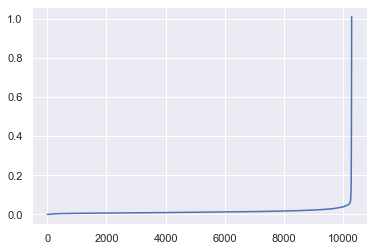

In [233]:
distances = np.sort(distances, axis=0)
distances = distances[:,1]
plt.plot(distances)
plt.show()

In [234]:
dbscan = DBSCAN(eps = 0.1, min_samples = 18)
pred = dbscan.fit_predict(df_wneighbors5[metric_features])
anom_index = np.where(pred == -1)
df_wneighbors5['CustID']=df_wneighbors5.index.copy()
df_wneighbors5.reset_index(inplace=True,drop=True)
df_wneighbors5.drop(anom_index[0],inplace=True)
df_wneighbors5.set_index('CustID',inplace=True)
scaled_feat=scaler.inverse_transform(df_wneighbors5.loc[df_wneighbors5.index][metric_features])  #reversing the scale
df_wneighbors5[metric_features]=scaled_feat
df_wneighbors5.drop(anom_index[0],inplace=True)
print('Percentage of data kept after removing outliers:', np.round(df_wneighbors5.shape[0] / df.shape[0], 4))

Percentage of data kept after removing outliers: 0.9883


<a class="anchor" id="isolation">

### 6. Isolation Forest
</a>

In [235]:
df_wneighbors6=df_wneighbors.copy()
model=IsolationForest(contamination=0.03,random_state=10) #expected proportion of outliers to be 3%
model.fit(df_wneighbors6.values)
anomaly=model.predict(df_wneighbors6.values)
anom_index=np.where(anomaly==-1)
df_wneighbors6.reset_index(inplace=True)
df_wneighbors6.drop(anom_index[0],inplace=True)
df_wneighbors6.set_index('CustID',inplace=True)
print('Percentage of data kept after removing outliers:', np.round(df_wneighbors6.shape[0] / df.shape[0], 4))

Percentage of data kept after removing outliers: 0.97


In [236]:
#we decided to use Knn with weights and z-score

df_clust=df_wneighbors4.copy()

<a class="anchor" id="afteroutlierimputation">

### Analysis of the Dataset after Outlier Detection and Data Imputation
</a>

In [237]:
ProfileReport(
    df,
    title='Dataset before outlier detection and data imputation',
    correlations={
        "pearson": {"calculate": True},
        "spearman": {"calculate": True},
        "kendall": {"calculate": False},
        "phi_k": {"calculate": False},
        "cramers": {"calculate": False},
    },                 
)

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

In [238]:
ProfileReport(
    df_clust,
    title='Dataset after outlier detection and data imputation',
    correlations={
        "pearson": {"calculate": True},
        "spearman": {"calculate": True},
        "kendall": {"calculate": False},
        "phi_k": {"calculate": False},
        "cramers": {"calculate": False},
    },                 
)

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

<a class="anchor" id="creation">
    
# Feature Creation
</a>

In [239]:
df_clust.columns

Index(['FirstPolYear', 'MonthSal', 'GeoLivArea', 'Children', 'CustMonVal',
       'ClaimsRate', 'PremMotor', 'PremHousehold', 'PremHealth', 'PremLife',
       'PremWork', 'HighSchool', 'BSc/MSc', 'PhD'],
      dtype='object')

In [240]:
df_clust['YearsCustomer']=2016-df_clust['FirstPolYear']
df_clust['CustValYear']=df_clust['CustMonVal']/df_clust['YearsCustomer']
df_clust['AnnualSal']=df_clust['MonthSal']*12
#df_clust['TotalPremiums']=df_clust['PremMotor']+df_clust['PremHousehold']+df_clust['PremHealth']+df_clust['PremLife']+df_clust['PremWork']
#df_clust['PerSalHealth']=df_clust['PremHealth']/df_clust['AnnualSal']
#df_clust['PerSalMotor']=df_clust['PremMotor']/df_clust['AnnualSal']   
#df_clust['PerSalHouse']=df_clust['PremHousehold']/df_clust['AnnualSal']
#df_clust['PerSalLife']=df_clust['PremLife']/df_clust['AnnualSal']
#df_clust['PerSalWork']=df_clust['PremWork']/df_clust['AnnualSal']
#df_clust['PerSalPremiums']=df_clust['TotalPremiums']/df_clust['AnnualSal']  
#df_clust['PerPremHealth']=df_clust['PremHealth']/df_clust['TotalPremiums']
#df_clust['PerPremMotor']=df_clust['PremMotor']/df_clust['TotalPremiums']  
#df_clust['PerPremHouse']=df_clust['PremHousehold']/df_clust['TotalPremiums']
#df_clust['PerPremLife']=df_clust['PremLife']/df_clust['TotalPremiums']
#df_clust['PerPremWork']=df_clust['PremWork']/df_clust['TotalPremiums']

<a class="anchor" id="selection">
    
# Feature Selection
</a>

In [241]:
#we kept YearsCustomer instead of FirstPolYear 
#we have kept AnnualSal instead of MothSal to be consistent as the premiums also correspond to yearly values
df_clust.drop(columns=['FirstPolYear','MonthSal'],inplace=True)

In [242]:
#we have decided to not use the following variables because they correspond to ratios and would be correlated to each other
#we prefered to use the original variables (that do not correspond to a ratio)
#as well as that, having AnnualSal and the premiums divided by each category gives us more information than using Total Premiums
#and PerSalPremiums
#'PerSalHealth','PerSalMotor','PerSalHouse','PerSalLife','PerSalWork','PerPremHealth','PerPremMotor'
#,'PerPremHouse','PerPremLife','PerPremWork'  

In [243]:
non_metric_features = ["HighSchool","BSc/MSc","PhD", "GeoLivArea", "Children"]  #updated the metric/non-metric features
metric_features = df_clust.columns.drop(non_metric_features).to_list()

<a class="anchor" id="filter">

## 1. Filter Methods
</a>

In [244]:
#here, we scale the data in order to be able to compare the variance between the metric features
df_minmax = df_clust.copy()
scaler = MinMaxScaler()
scaled_feat = scaler.fit_transform(df_minmax[metric_features])

df_minmax[metric_features] = scaled_feat

<a class="anchor" id="variance">

### 1.1 Variance of the Metric Features
</a>

In [245]:
df_minmax[metric_features].var() #there are no univariate variables

CustMonVal       0.001195
ClaimsRate       0.001172
PremMotor        0.053703
PremHousehold    0.022153
PremHealth       0.027804
PremLife         0.036189
PremWork         0.031293
YearsCustomer    0.075579
CustValYear      0.001056
AnnualSal        0.042798
dtype: float64

<a class="anchor" id="association">

### 1.2 Association Measures
</a>

In [246]:
#analysing the association measures between the features
ProfileReport(  
    df_clust,    
    title='Analyzing association measures',
    correlations={
        "pearson": {"calculate": True},
        "spearman": {"calculate": True},
        "kendall": {"calculate": True},
        "phi_k": {"calculate": True},
        "cramers": {"calculate": True},
    },                 
)

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

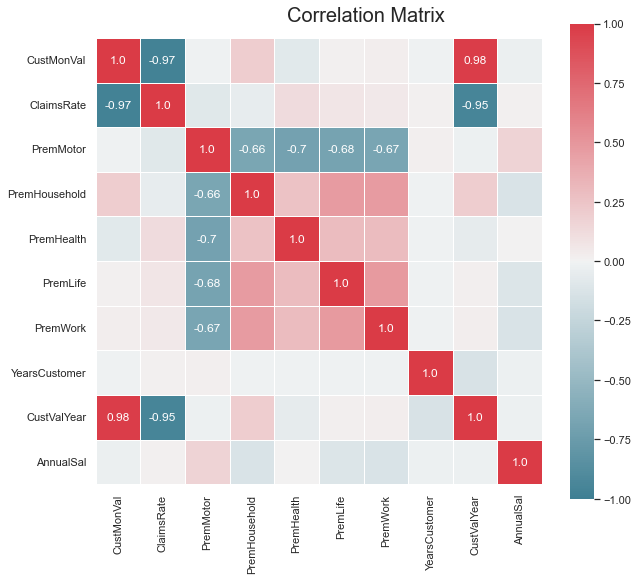

In [247]:
draw_pretty_correlation(df_minmax, metric_features, "Correlation Matrix")

<a class="anchor" id="scaling">

# Feature Scaling
</a>

<a class="anchor" id="minmax">

### 1. MinMax Scaler
</a>

In [248]:
#we have already scaled in the section above
df_minmax

,GeoLivArea,Children,CustMonVal,ClaimsRate,PremMotor,PremHousehold,PremHealth,PremLife,PremWork,HighSchool,BSc/MSc,PhD,YearsCustomer,CustValYear,AnnualSal
CustID,,,,,,,,,,,,,,,
1,1.0,1.0,0.858030,0.039514,0.642237,0.102004,0.333663,0.252077,0.124029,1.0,0.0,0.0,0.541667,0.797965,0.393345
2,4.0,1.0,0.790397,0.113475,0.132360,0.324406,0.266984,0.940353,0.507148,1.0,0.0,0.0,0.708333,0.744381,0.073379
3,3.0,0.0,0.874367,0.028369,0.352261,0.197801,0.284716,0.435686,0.476624,0.0,0.0,0.0,0.291667,0.824355,0.414676
4,4.0,1.0,0.805471,0.100304,0.311814,0.078163,0.704047,0.197610,0.173185,0.0,1.0,0.0,0.333333,0.754717,0.163396
5,4.0,1.0,0.812368,0.091185,0.578620,0.081102,0.415084,0.120321,0.229468,0.0,1.0,0.0,0.500000,0.760824,0.305034
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10292,2.0,0.0,0.807701,0.097264,0.672807,0.082191,0.395352,0.078316,0.114970,0.0,0.0,1.0,0.583333,0.756889,0.609002
10293,3.0,0.0,0.993352,0.000000,0.228256,0.733580,0.326674,0.092831,0.502855,0.0,0.0,0.0,0.875000,0.877332,0.447526
10294,1.0,1.0,0.876933,0.021277,0.689706,0.137239,0.324426,0.091804,0.072511,0.0,1.0,0.0,0.166667,0.836504,0.551408


<a class="anchor" id="standard">

### 2. Standard Scaler
</a>

In [249]:
#scale the data using Standard Scaler
df_standard = df_clust.copy()
final_scaler = StandardScaler()
scaled_feat = final_scaler.fit_transform(df_standard[metric_features])
scaled_feat
df_standard[metric_features] = scaled_feat
df_standard.head()  #we have decided to use this scaler

,GeoLivArea,Children,CustMonVal,ClaimsRate,PremMotor,PremHousehold,PremHealth,PremLife,PremWork,HighSchool,BSc/MSc,PhD,YearsCustomer,CustValYear,AnnualSal
CustID,,,,,,,,,,,,,,,
1,1.0,1.0,0.632234,-0.861894,0.548405,-0.535785,-0.308837,0.211942,-0.517504,1.0,0.0,0.0,0.154300,0.483649,-0.358697
2,4.0,1.0,-1.324480,1.298674,-1.651923,0.958553,-0.708742,3.830158,1.648352,1.0,0.0,0.0,0.760574,-1.165660,-1.905428
3,3.0,0.0,1.104887,-1.187459,-0.702963,0.107879,-0.602397,1.177159,1.475792,0.0,0.0,0.0,-0.755110,1.295908,-0.255582
4,4.0,1.0,-0.888356,0.913915,-0.877506,-0.695980,1.912543,-0.074385,-0.239612,0.0,1.0,0.0,-0.603542,-0.847531,-1.470281
5,4.0,1.0,-0.688825,0.647544,0.273871,-0.676233,0.179487,-0.480689,0.078568,0.0,1.0,0.0,0.002732,-0.659541,-0.785595


<a class="anchor" id="robust">

### 3. Robust Scaler
</a>

In [250]:
df_robust=df_clust.copy()

In [251]:
#scale the data using Robust Scaler
scaler = RobustScaler()
scaled_feat = scaler.fit_transform(df_robust[metric_features])
scaled_feat

array([[ 0.4778448 , -0.55932203,  0.34386846, ...,  0.08333333,
         0.43908481, -0.228701  ],
       [-0.78033979,  0.6779661 , -1.07003412, ...,  0.41666667,
        -0.72533221, -1.2005183 ],
       [ 0.7817648 , -0.74576271, -0.4602445 , ..., -0.41666667,
         1.01254215, -0.16391318],
       ...,
       [ 0.8295026 , -0.86440678,  0.47550227, ..., -0.66666667,
         1.27655781,  0.25137674],
       [ 0.15618589, -0.11864407, -0.54345148, ...,  0.41666667,
         0.06548581, -0.36216391],
       [ 0.68122796, -0.76271186,  0.52501895, ..., -0.33333333,
         0.84188256,  0.18464529]])

In [252]:
df_robust[metric_features] = scaled_feat
df_robust.head()

,GeoLivArea,Children,CustMonVal,ClaimsRate,PremMotor,PremHousehold,PremHealth,PremLife,PremWork,HighSchool,BSc/MSc,PhD,YearsCustomer,CustValYear,AnnualSal
CustID,,,,,,,,,,,,,,,
1,1.0,1.0,0.477845,-0.559322,0.343868,-0.212917,-0.164940,0.506315,-0.176778,1.0,0.0,0.0,0.083333,0.439085,-0.228701
2,4.0,1.0,-0.780340,0.677966,-1.070034,1.237029,-0.441893,3.832206,1.850943,1.0,0.0,0.0,0.416667,-0.725332,-1.200518
3,3.0,0.0,0.781765,-0.745763,-0.460245,0.411625,-0.368244,1.393550,1.689389,0.0,0.0,0.0,-0.416667,1.012542,-0.163913
4,4.0,1.0,-0.499908,0.457627,-0.572403,-0.368353,1.373471,0.243121,0.083390,0.0,1.0,0.0,-0.333333,-0.500732,-0.927114
5,4.0,1.0,-0.371608,0.305085,0.167456,-0.349193,0.173247,-0.130356,0.381277,0.0,1.0,0.0,0.000000,-0.368010,-0.496923


<a class="anchor" id="remainingoutliers">

# Detection of the Remaining Outliers in our Dataset (using DBSCAN)
</a>

In [253]:
ProfileReport(
    df_standard,
    title='Remaining outliers',
    correlations={
        "pearson": {"calculate": True},
        "spearman": {"calculate": True},
        "kendall": {"calculate": False},
        "phi_k": {"calculate": False},
        "cramers": {"calculate": False},
    },                 
)

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

In [254]:
neigh = NearestNeighbors(n_neighbors=19)
nbrs = neigh.fit(df_standard[metric_features])

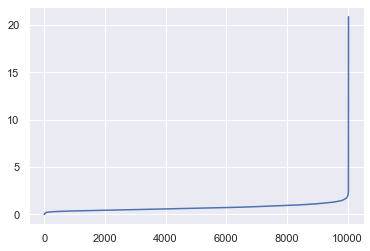

In [255]:
distances, indices = nbrs.kneighbors(df_standard[metric_features])
distances = np.sort(distances, axis=0)
distances = distances[:,1]
plt.plot(distances)
plt.show()

In [256]:
dbscan = DBSCAN(eps = 2, min_samples = 20)
pred = dbscan.fit_predict(df_standard[metric_features])
anom_index = np.where(pred == -1)
df_standard['CustID']=df_standard.index.copy()
df_standard.reset_index(inplace=True,drop=True)
df_out_2=df_standard.copy()
df_out_2=df_out_2.iloc[anom_index[0],:]
df_out_2.set_index('CustID',inplace=True)
df_standard.drop(anom_index[0],inplace=True)
df_standard.set_index('CustID',inplace=True)
print('Percentage of data kept after removing outliers:', np.round(df_standard.shape[0] / df_original.shape[0], 4))

Percentage of data kept after removing outliers: 0.9593


In [257]:
ProfileReport(
    df_standard,
    title='Analysis after removing the outliers',
    correlations={
        "pearson": {"calculate": True},
        "spearman": {"calculate": True},
        "kendall": {"calculate": False},
        "phi_k": {"calculate": False},
        "cramers": {"calculate": False},
    },                 
)

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

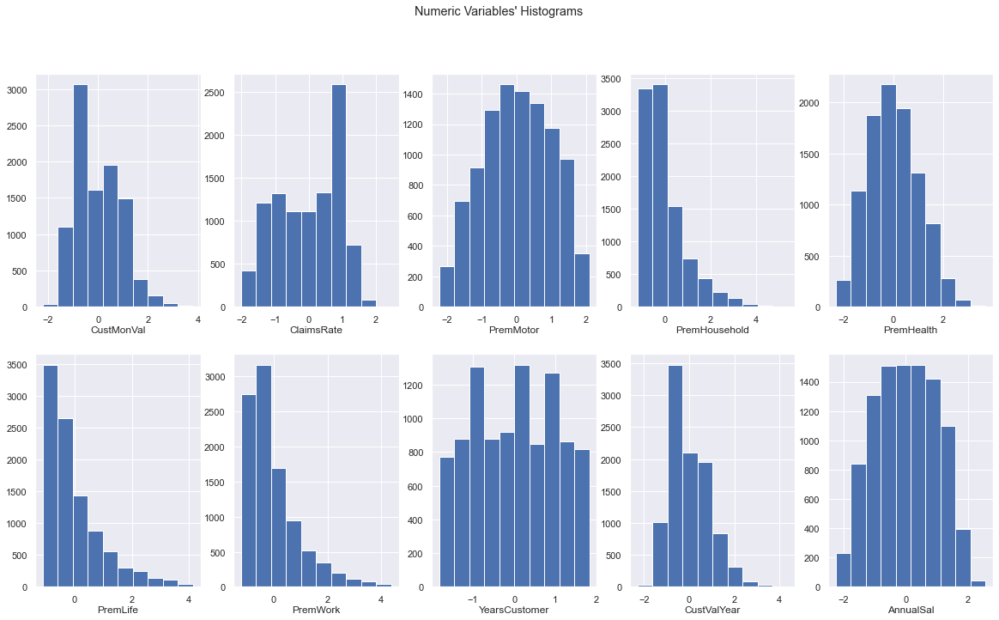

In [258]:
draw_histogram(2, ceil(len(metric_features) / 2), (20, 11), df_standard, metric_features, "Numeric Variables' Histograms")

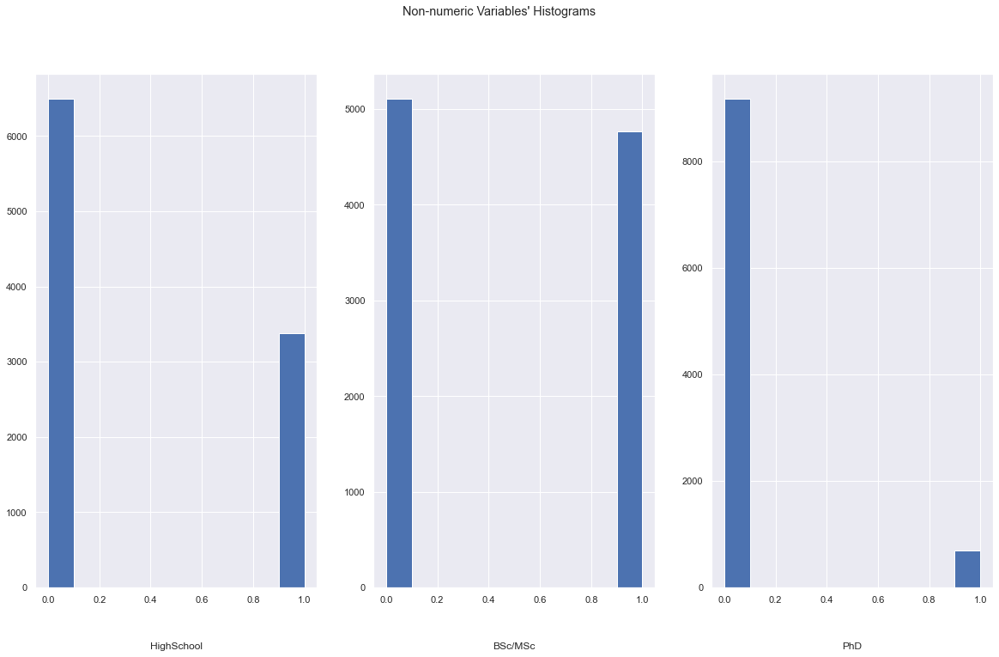

In [259]:
draw_histogram(1, ceil(len(non_metric_features) / 2), (20, 11), df_standard, non_metric_features, "Non-numeric Variables' Histograms")

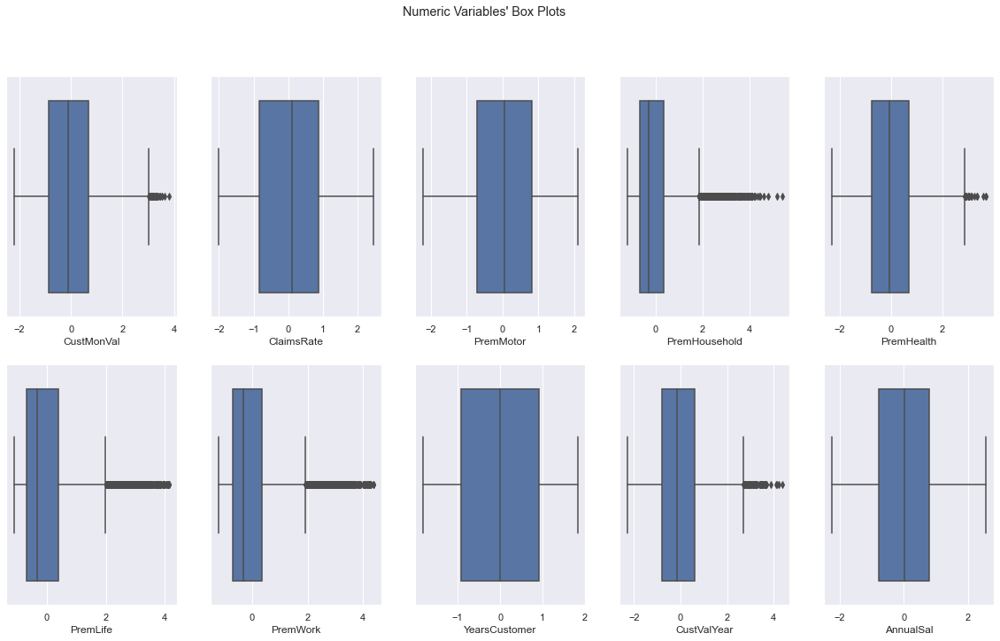

In [260]:
draw_boxplot(2, ceil(len(metric_features) / 2), (20, 11), df_standard, metric_features, "Numeric Variables' Box Plots")

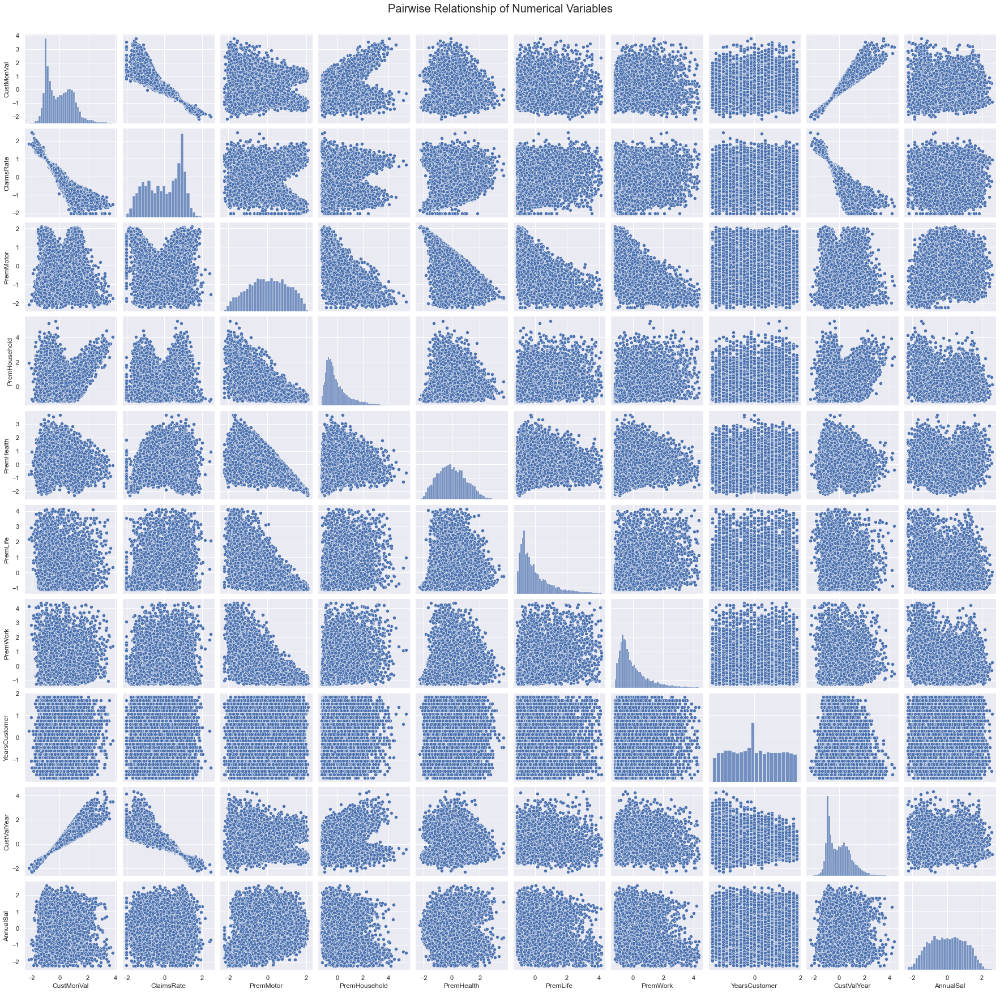

In [261]:
draw_parwise_relationship(df_standard, metric_features, "Pairwise Relationship of Numerical Variables")

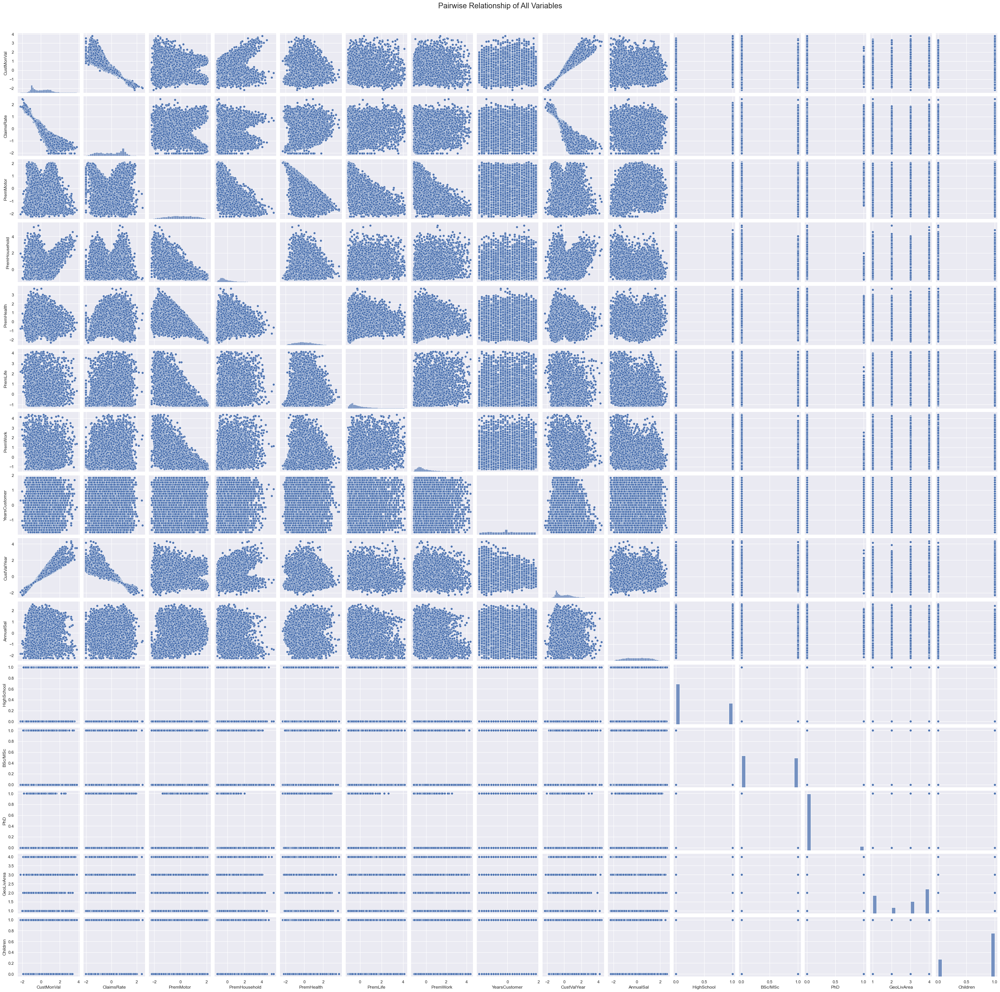

In [262]:
draw_parwise_relationship(df_standard, metric_features+non_metric_features, "Pairwise Relationship of All Variables")

<a class="anchor" id="clustering">

# Clustering by Perspectives
</a>

In [263]:
def cluster_profiles(df, label_columns, figsize, compar_titles=None):
    """
    Pass df with labels columns of one or multiple clustering labels. 
    Then specify this label columns to perform the cluster profile according to them.
    """
    if compar_titles == None:
        compar_titles = [""]*len(label_columns)
        
    sns.set()
    fig, axes = plt.subplots(nrows=len(label_columns), ncols=2, figsize=figsize, squeeze=False)
    for ax, label, titl in zip(axes, label_columns, compar_titles):
        #filtering df
        drop_cols = [i for i in label_columns if i!=label]
        dfax = df.drop(drop_cols, axis=1)
        
        #getting the cluster centroids and counts
        centroids = dfax.groupby(by=label, as_index=False).mean()
        counts = dfax.groupby(by=label, as_index=False).count().iloc[:,[0,1]]
        counts.columns = [label, "counts"]
        
        #setting Data
        pd.plotting.parallel_coordinates(centroids, label, color=sns.color_palette(), ax=ax[0])
        sns.barplot(x=label, y="counts", data=counts, ax=ax[1])

        #setting Layout
        handles, _ = ax[0].get_legend_handles_labels()
        cluster_labels = ["Cluster {}".format(i) for i in range(len(handles))]
        ax[0].annotate(text=titl, xy=(0.95,1.1), xycoords='axes fraction', fontsize=13, fontweight = 'heavy') 
        ax[0].legend(handles, cluster_labels) #adaptable to number of clusters
        ax[0].axhline(color="black", linestyle="--")
        ax[0].set_title("Cluster Means - {} Clusters".format(len(handles)), fontsize=13)
        ax[0].set_xticklabels(ax[0].get_xticklabels(), rotation=-20)
        ax[1].set_xticklabels(cluster_labels)
        ax[1].set_xlabel("")
        ax[1].set_ylabel("Absolute Frequency")
        ax[1].set_title("Cluster Sizes - {} Clusters".format(len(handles)), fontsize=13)
    
    plt.subplots_adjust(hspace=0.4, top=0.90)
    plt.suptitle("Cluster Simple Profilling", fontsize=23)
    plt.show()

<a class="anchor" id="demographic">

## 1. Demographic Perspective
</a>

<a class="anchor" id="kprototypes">

### 1.1 K-prototypes
</a>

In [264]:
#we have decided to not use GeoLivArea
personal_feat=['AnnualSal','HighSchool','BSc/MSc','PhD','Children']
df_demo=df_standard[personal_feat].copy()
df_demo.columns

Index(['AnnualSal', 'HighSchool', 'BSc/MSc', 'PhD', 'Children'], dtype='object')

In [265]:
#choose optimal K using Elbow method
cost = []

for n_clus in range(1,6):  #iterate over desired ncluster range
    kproto = KPrototypes(n_clusters= n_clus, init='Huang',n_jobs = 1, random_state= 10)
    clusters = kproto.fit_predict(df_demo, categorical=[1,2,3,4])
    cost.append(kproto.cost_)  #save the inertia of the given cluster solution
    print('Cost', n_clus, 'clusters =', kproto.cost_)

Cost 1 clusters = 15585.322685507172
Cost 2 clusters = 8384.908169807803
Cost 3 clusters = 6263.705325580741
Cost 4 clusters = 4761.746488568243
Cost 5 clusters = 3960.5621425412505


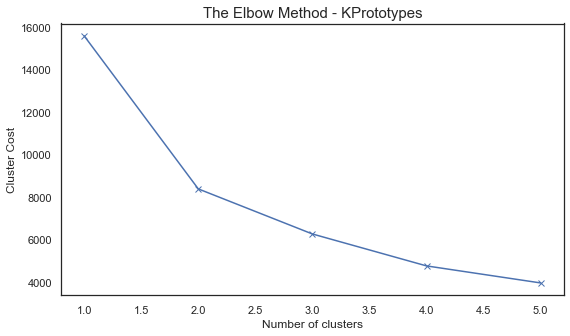

In [266]:
sns.set_style("white")
range_K=range(1,6)
plt.figure(figsize=(9,5))
plt.plot(range_K, cost, 'bx-')
pd.Series(cost,index=range_K)
plt.xlabel('Number of clusters')
plt.ylabel('Cluster Cost')
plt.title('The Elbow Method - KPrototypes', size=15)
plt.show()

In [267]:
k2prot = KPrototypes(n_jobs=1, n_clusters = 2, init = 'Huang', random_state=10)  #seeing the results for 2 clusters
k2prot_labels = k2prot.fit_predict(df_demo, categorical = [1,2,3,4])

In [268]:
k3prot = KPrototypes(n_jobs=1, n_clusters = 3, init = 'Huang', random_state=10)  #seeing the results for 3 clusters
k3prot_labels = k3prot.fit_predict(df_demo, categorical = [1,2,3,4])

In [269]:
df_prot_demo = pd.concat([df_demo, pd.DataFrame(k2prot_labels,index = df_demo.index).rename(columns = {0:'Cluster (with 2 in total)'}), 
                    pd.DataFrame(k3prot_labels,index = df_demo.index).rename(columns = {0:'Cluster (with 3 in total)'})], axis=1)

In [270]:
df_prot_demo.groupby('Cluster (with 2 in total)')[personal_feat].mean()

,AnnualSal,HighSchool,BSc/MSc,PhD,Children
Cluster (with 2 in total),,,,,
0,0.954801,0.300634,0.562075,0.068763,0.447548
1,-0.710024,0.373575,0.422009,0.071403,0.910434


In [271]:
df_prot_demo.groupby('Cluster (with 3 in total)')[personal_feat].mean()

,AnnualSal,HighSchool,BSc/MSc,PhD,Children
Cluster (with 3 in total),,,,,
0,-0.055344,0.151047,0.720339,0.060070,0.919990
1,-1.105940,0.557178,0.206465,0.064303,0.876955
2,1.166248,0.391566,0.428715,0.089692,0.269746


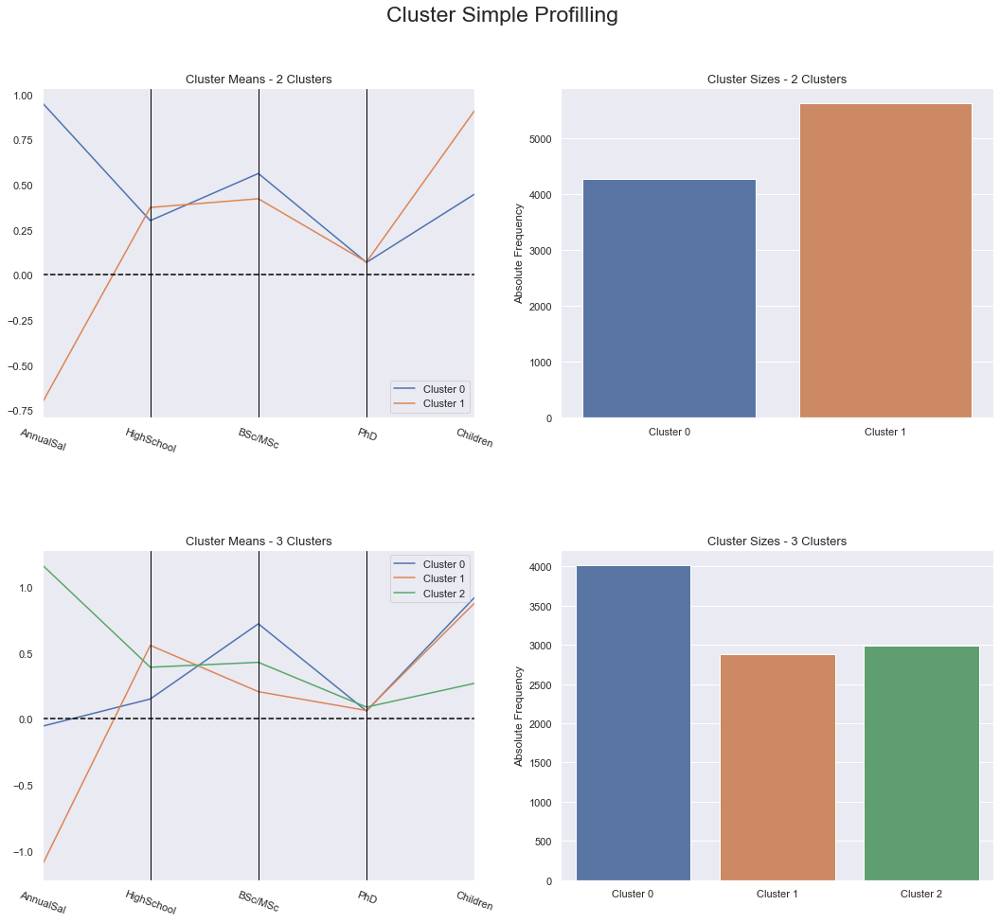

In [272]:
cluster_profiles(df_prot_demo, ['Cluster (with 2 in total)', 'Cluster (with 3 in total)'], (18, 15)) #we decided to use 3 clusters

<a class="anchor" id="behavioral">

## 2. Behavioral Perspective
</a>

In [273]:
def get_ss(df):
    ss = np.sum(df.var() * (df.count() - 1))
    return ss  #return sum of sum of squares of each df variable

<a class="anchor" id="kmeans">

### 2.1 K-means
</a>

In [274]:
#determining which features to use using k-means
behavioral_feat=['CustValYear','PremMotor','PremHousehold','PremHealth','PremLife','PremWork']
df_behavioral=df_standard[behavioral_feat].copy()
df_behavioral

,CustValYear,PremMotor,PremHousehold,PremHealth,PremLife,PremWork
CustID,,,,,,
1,0.483649,0.548405,-0.535785,-0.308837,0.211942,-0.517504
2,-1.165660,-1.651923,0.958553,-0.708742,3.830158,1.648352
3,1.295908,-0.702963,0.107879,-0.602397,1.177159,1.475792
4,-0.847531,-0.877506,-0.695980,1.912543,-0.074385,-0.239612
5,-0.659541,0.273871,-0.676233,0.179487,-0.480689,0.078568
...,...,...,...,...,...,...
10290,0.061684,-0.543168,0.312449,-0.112591,1.515255,0.769050
10292,-0.780676,0.680326,-0.668911,0.061146,-0.701506,-0.568713
10294,1.669866,0.753255,-0.299043,-0.364233,-0.630599,-0.808744


In [275]:
inertia = []
silhouette = []
for n_clus in list(range(2,15)):  #iterate over desired ncluster range
    kmclust =  KMeans(n_clusters=n_clus,init='k-means++',n_init=100,random_state=10)
    #fit the clusterer
    kmclust.fit(df_behavioral)
    inertia.append(kmclust.inertia_)  #save the inertia of the given cluster solution
    silhouette.append(silhouette_score(df_behavioral, kmclust.labels_))   #save the silhouette score of the given cluster solution

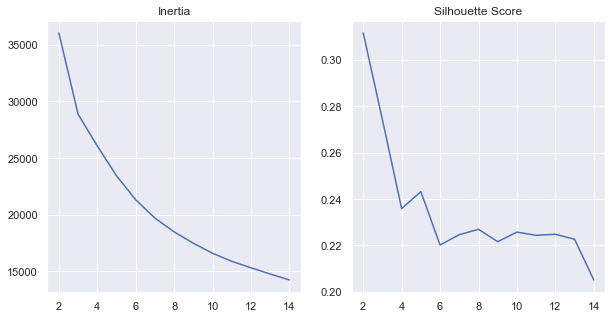

In [276]:
fig, ax = plt.subplots(1,2, figsize=(10,5))
ax[0].plot(pd.Series(inertia,index=range(2,15)))
ax[0].set_title('Inertia') 
ax[1].plot(pd.Series(silhouette,index=range(2,15)))
ax[1].set_title('Silhouette Score')
plt.show()

In [277]:
km_prod =  KMeans(n_clusters=3,init='k-means++',n_init=100,random_state=10)  #using 3 clusters
km_labels=km_prod.fit_predict(df_behavioral)

In [278]:
df_km_behavioral = pd.concat([df_behavioral, pd.DataFrame(km_labels,index = df_behavioral.index).rename(columns = {0:'Cluster'})],axis=1)

In [279]:
df_km_behavioral.groupby('Cluster').mean()

,CustValYear,PremMotor,PremHousehold,PremHealth,PremLife,PremWork
Cluster,,,,,,
0,0.364421,-1.185315,1.277659,0.057003,1.244068,1.216964
1,0.004246,0.985648,-0.555794,-0.807881,-0.584453,-0.581570
2,-0.209138,-0.407131,-0.107694,0.841830,-0.018632,-0.023078


In [280]:
#computing the R^2 of the cluster solution
sst = get_ss(df_behavioral)  #get total sum of squares
ssw_labels = df_km_behavioral.groupby(by='Cluster').apply(get_ss)  #compute ssw for each cluster labels
ssb = sst - np.sum(ssw_labels) 
r2 = ssb / sst
print("Cluster solution with R^2 of %0.4f" % r2)

Cluster solution with R^2 of 0.4729


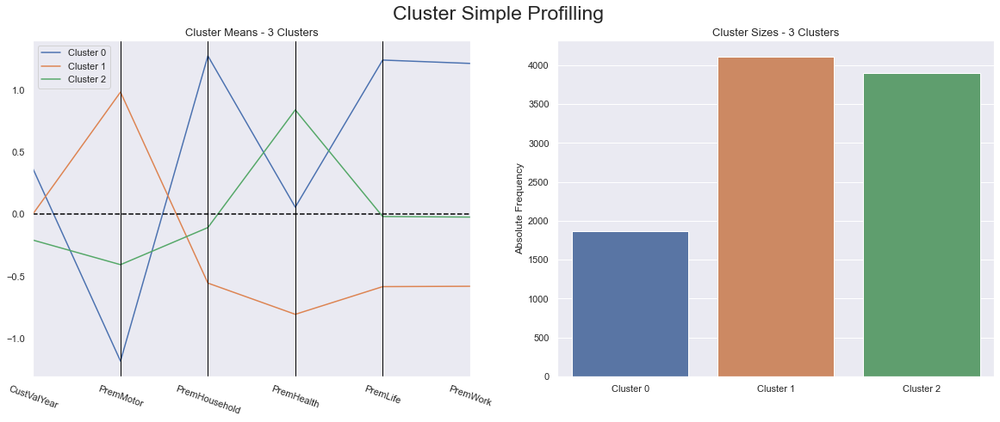

In [281]:
cluster_profiles(df_km_behavioral,['Cluster'], (20, 7))

<a class="anchor" id="hkm">

### 2.2 K-means and Hierarchical Clustering
</a>

In [282]:
k_means = KMeans(n_clusters=20,random_state=10)  #using 20 clusters
hkm_labels = k_means.fit_predict(df_behavioral)
df_hkm_behavioral = pd.concat((df_behavioral, pd.DataFrame(hkm_labels,index = df_behavioral.index).rename(columns = {0:'Initial Cluster'})), axis = 1)

In [283]:
hkm_centroids=df_hkm_behavioral.groupby('Initial Cluster').mean()

In [284]:
def get_r2_hc(df, link_method, max_nclus, min_nclus=1, dist="euclidean"):
    """This function computes the R2 for a set of cluster solutions given by the application of a hierarchical method.
    The R2 is a measure of the homogenity of a cluster solution. It is based on SSt = SSw + SSb and R2 = SSb/SSt. 
    
    Parameters:
    df (DataFrame): Dataset to apply clustering
    link_method (str): either "ward", "complete", "average", "single"
    max_nclus (int): maximum number of clusters to compare the methods
    min_nclus (int): minimum number of clusters to compare the methods. Defaults to 1.
    dist (str): distance to use to compute the clustering solution. Must be a valid distance. Defaults to "euclidean".
    
    Returns:
    ndarray: R2 values for the range of cluster solutions
    """
    
    sst = get_ss(df)  #get total sum of squares
    
    r2 = []  #where we will store the R2 metrics for each cluster solution
    
    for i in range(min_nclus, max_nclus+1):  # iterate over desired ncluster range
        cluster = AgglomerativeClustering(n_clusters=i, linkage=link_method)
        
        
        hclabels = cluster.fit_predict(df) #get cluster labels
        
        
        df_concat = pd.concat((df, pd.Series(hclabels, name='labels')), axis=1)  #concat df with labels
        
        
        ssw_labels = df_concat.groupby(by='labels').apply(get_ss)  #compute ssw for each cluster labels
        
        
        ssb = sst - np.sum(ssw_labels)  
        
        
        r2.append(ssb / sst)  #save the R2 of the given cluster solution
        
    return np.array(r2)

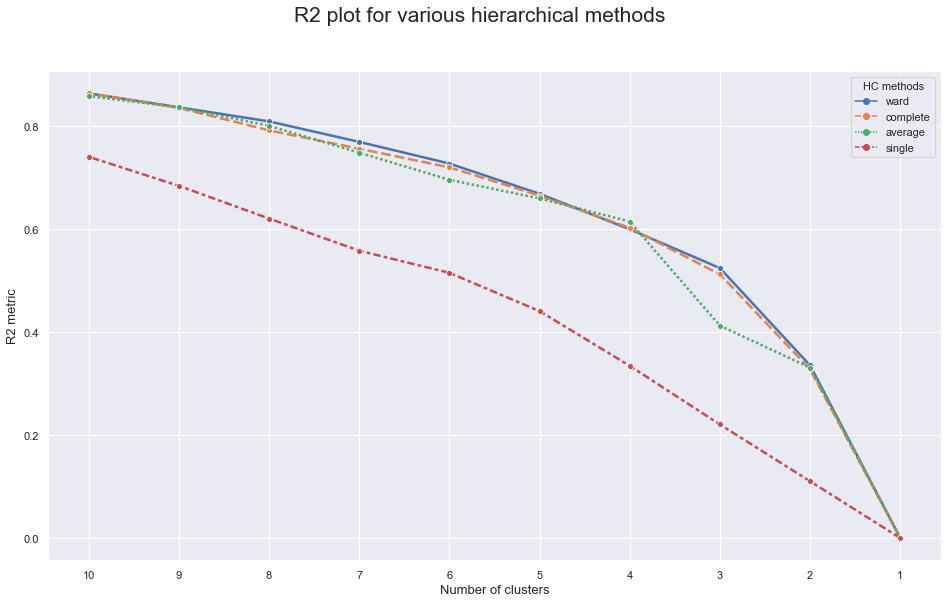

In [285]:
hc_methods = ["ward", "complete", "average", "single"]
#call function defined above to obtain the R2 statistic for each hc_method
max_nclus = 10
r2_hc_methods = np.vstack(
    [
        get_r2_hc(df=hkm_centroids, link_method=link, max_nclus=max_nclus) 
        for link in hc_methods
    ]
).T
r2_hc_methods = pd.DataFrame(r2_hc_methods, index=range(1, max_nclus + 1), columns=hc_methods)

sns.set()
#plot data
fig = plt.figure(figsize=(16,9))
sns.lineplot(data=r2_hc_methods, linewidth=2.5, markers=["o"]*4)

#finalize the plot
fig.suptitle("R2 plot for various hierarchical methods", fontsize=21)
plt.gca().invert_xaxis()  #invert x axis
plt.legend(title="HC methods", title_fontsize=11)
plt.xticks(range(1, max_nclus + 1))
plt.xlabel("Number of clusters", fontsize=13)
plt.ylabel("R2 metric", fontsize=13)

plt.show()

In [286]:
#setting distance_threshold=0 and n_clusters=None ensures we compute the full tree
linkage = 'ward'
distance='euclidean'
hclust = AgglomerativeClustering(linkage=linkage, affinity=distance, distance_threshold=0, n_clusters=None)
hclust.fit_predict(hkm_centroids)

array([15, 16, 19, 12, 17, 18, 10,  8, 11,  5, 13,  9, 14,  7,  6,  4,  3,
        1,  2,  0], dtype=int64)

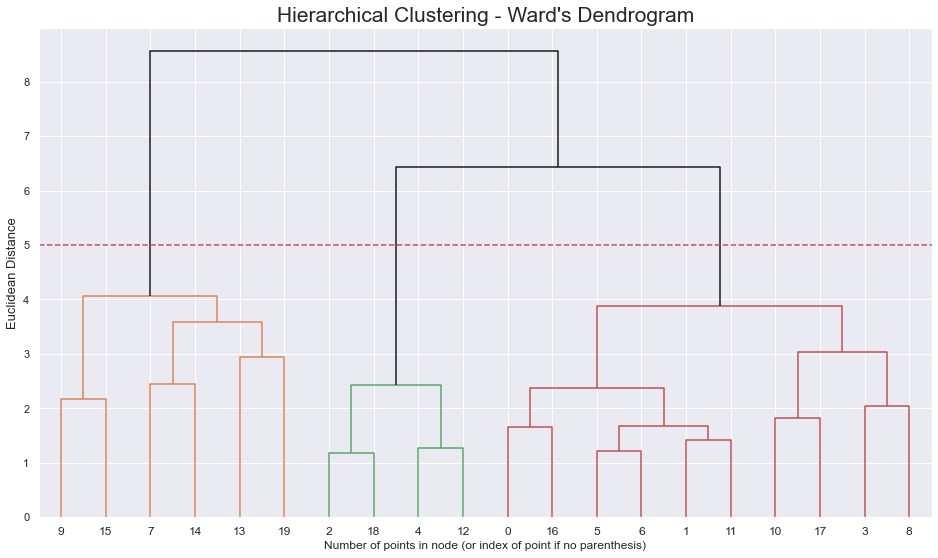

In [287]:
#create the counts of samples under each node (number of points being merged)
counts = np.zeros(hclust.children_.shape[0])
n_samples = len(hclust.labels_)

#hclust.children_ contains the observation ids that are being merged together
#at the i-th iteration, children[i][0] and children[i][1] are merged to form node n_samples + i
for i, merge in enumerate(hclust.children_):
    #track the number of observations in the current cluster being formed
    current_count = 0
    for child_idx in merge:
        if child_idx < n_samples:
            #if this is True, then we are merging an observation
            current_count += 1  #leaf node
        else:
            #otherwise, we are merging a previously formed cluster
            current_count += counts[child_idx - n_samples]
    counts[i] = current_count

#the hclust.children_ is used to indicate the two points/clusters being merged (dendrogram's u-joins)
#the hclust.distances_ indicates the distance between the two points/clusters (height of the u-joins)
#the counts indicate the number of points being merged (dendrogram's x-axis)
linkage_matrix = np.column_stack(
    [hclust.children_, hclust.distances_, counts]
).astype(float)

#plot the corresponding dendrogram
sns.set()
fig = plt.figure(figsize=(16,9))
y_threshold = 5
dendrogram(linkage_matrix, truncate_mode='level', p=5, color_threshold=y_threshold, above_threshold_color='k')
plt.hlines(y_threshold, 0, 1000, colors="r", linestyles="dashed")
plt.title(f'Hierarchical Clustering - {linkage.title()}\'s Dendrogram', fontsize=21)
plt.xlabel('Number of points in node (or index of point if no parenthesis)')
plt.ylabel(f'{distance.title()} Distance', fontsize=13)
plt.show()

In [288]:
#3 cluster solution
linkage = 'ward'
hkm = AgglomerativeClustering(linkage=linkage, affinity='euclidean', n_clusters=3)
hkm_labels = hkm.fit_predict(hkm_centroids)

In [289]:
hkm_centroids['Final Cluster'] = hkm_labels
hkm_centroids   #centroid's cluster labels

,CustValYear,PremMotor,PremHousehold,PremHealth,PremLife,PremWork,Final Cluster
Initial Cluster,,,,,,,
0,-0.328067,-0.854048,-0.194537,1.870293,-0.195871,-0.162046,1
1,-0.049194,0.121634,0.178491,-0.401064,0.465981,-0.274391,1
2,0.964103,1.469215,-0.766451,-1.363246,-0.783473,-0.772416,2
3,0.175863,-0.468064,0.260761,-0.405785,0.799891,1.263515,1
4,-0.855694,1.419969,-0.726252,-1.310724,-0.769966,-0.754767,2
5,-0.673678,-0.084489,-0.452053,0.821372,-0.285588,-0.455485,1
6,0.436781,0.181698,-0.408837,0.447786,-0.502504,-0.452286,1
7,-0.767250,-1.569534,2.546639,-0.328446,2.255176,0.780970,0
8,-0.495308,-1.124186,0.126306,0.859864,-0.149888,2.159322,1


In [290]:
#mapper between initial and final clusters
cluster_mapper = hkm_centroids['Final Cluster'].to_dict()

#mapping the final clusters on the centroids to the observations
df_hkm_behavioral['Final Cluster'] = df_hkm_behavioral.apply(
    lambda row: cluster_mapper[(row['Initial Cluster'])], axis=1)

df_hkm_behavioral.drop('Initial Cluster', axis=1, inplace=True)

In [291]:
df_hkm_behavioral.groupby('Final Cluster').mean()

,CustValYear,PremMotor,PremHousehold,PremHealth,PremLife,PremWork
Final Cluster,,,,,,
0,0.497209,-1.254656,1.740194,0.014431,1.110577,1.156776
1,-0.125750,-0.403983,-0.066865,0.639917,0.156674,0.113240
2,-0.035761,1.061580,-0.608487,-0.858989,-0.646918,-0.619210


In [292]:
#computing the R^2 of the cluster solution
sst = get_ss(df_behavioral)  #get total sum of squares
ssw_labels = df_hkm_behavioral.groupby(by='Final Cluster').apply(get_ss)  #compute ssw for each cluster labels
ssb = sst - np.sum(ssw_labels)  
r2 = ssb / sst
print("Cluster solution with R^2 of %0.4f" % r2)

Cluster solution with R^2 of 0.4312


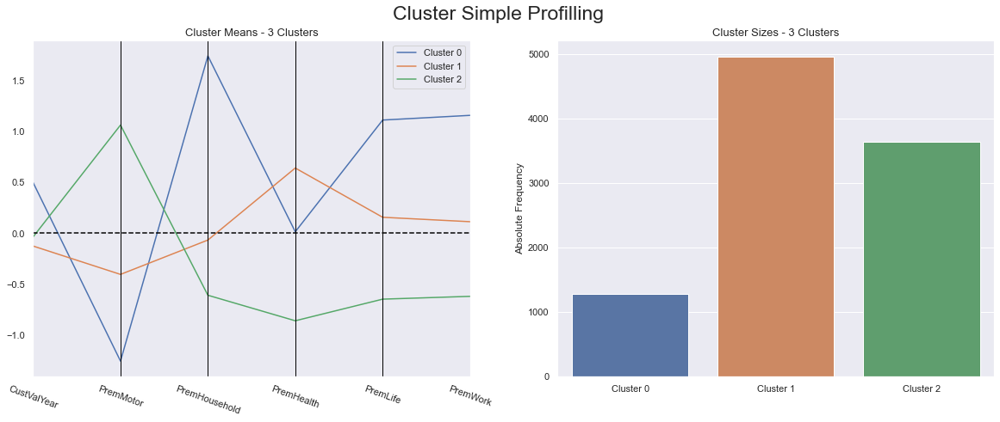

In [293]:
cluster_profiles(df_hkm_behavioral, ['Final Cluster'], (20,7))

<a class="anchor" id="gmm">

### 2.3 Gaussian Mixture Model
</a>

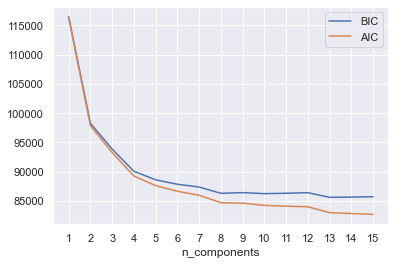

In [294]:
#selecting number of components based on AIC and BIC
n_components = np.arange(1, 16)
models = [GaussianMixture(n, covariance_type='full', n_init=10, random_state=10).fit(df_behavioral)
          for n in n_components]

bic_values = [gmm.bic(df_behavioral) for gmm in models]
aic_values = [gmm.aic(df_behavioral) for gmm in models]
plt.plot(n_components, bic_values, label='BIC')
plt.plot(n_components, aic_values, label='AIC')
plt.legend(loc='best')
plt.xlabel('n_components')
plt.xticks(n_components)
plt.show()           

In [295]:
gmm = GaussianMixture(n_components=3,covariance_type='full',n_init=3,init_params='kmeans',random_state=10)
gmm_labels = gmm.fit_predict(df_behavioral)

In [296]:
#characterizing the 3 clusters
df_gmm_behavioral = pd.concat((df_behavioral,pd.DataFrame(gmm_labels,index = df_behavioral.index).rename(columns = {0:'Cluster'})), axis=1)
df_gmm_behavioral.groupby('Cluster').mean()

,CustValYear,PremMotor,PremHousehold,PremHealth,PremLife,PremWork
Cluster,,,,,,
0,-0.124177,-0.220948,-0.075742,0.493507,-0.009098,-0.025486
1,-0.036737,0.991024,-0.657078,-0.643149,-0.692554,-0.674137
2,0.255627,-1.169827,1.146204,0.170594,1.155211,1.128865


In [297]:
#computing the R^2 of the cluster solution
sst = get_ss(df_behavioral)  #get total sum of squares
ssw_labels = df_gmm_behavioral.groupby(by='Cluster').apply(get_ss)  #compute ssw for each cluster labels
ssb = sst - np.sum(ssw_labels)  
r2 = ssb / sst
print("Cluster solution with R^2 of %0.4f" % r2)

Cluster solution with R^2 of 0.4109


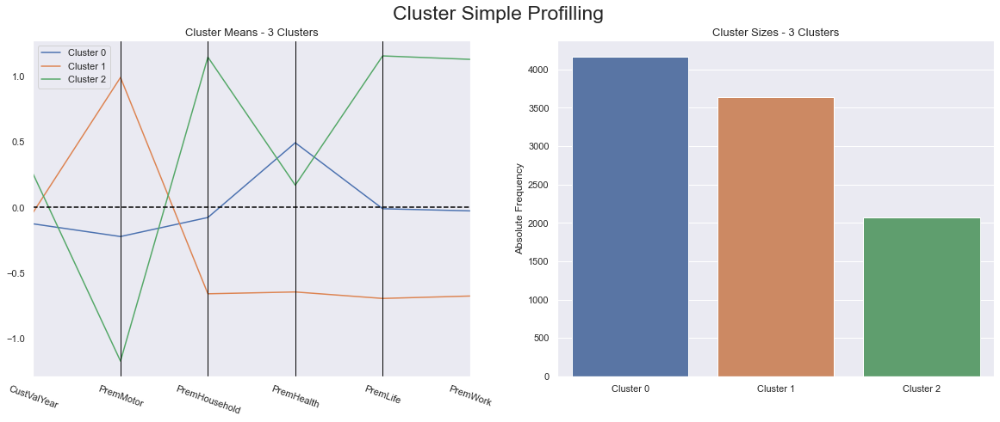

In [298]:
cluster_profiles(df_gmm_behavioral, ['Cluster'], (20,7))

<a class="anchor" id="ksom">

### 2.4 Self-organizing Map and K-means
</a>

In [299]:
np.random.seed(10)  #rectangular lattice led to a lower quantization error

sm = sompy.SOMFactory().build(
    df_behavioral.values, 
    mapsize=[20, 20],  
    initialization='random', 
    neighborhood='gaussian',
    training='batch',
    lattice='rect',
    component_names=df_behavioral.columns
)
sm.train(n_job=4, verbose='info', train_rough_len=100, train_finetune_len=100)

 Training...
 random_initialization took: 0.000000 seconds
 Rough training...
 radius_ini: 7.000000 , radius_final: 1.166667, trainlen: 100

 epoch: 1 ---> elapsed time:  0.046000, quantization error: 1.730492

 epoch: 2 ---> elapsed time:  0.044000, quantization error: 1.913958

 epoch: 3 ---> elapsed time:  0.044000, quantization error: 1.454205

 epoch: 4 ---> elapsed time:  0.044000, quantization error: 1.399637

 epoch: 5 ---> elapsed time:  0.045000, quantization error: 1.374461

 epoch: 6 ---> elapsed time:  0.048000, quantization error: 1.364897

 epoch: 7 ---> elapsed time:  0.046000, quantization error: 1.357664

 epoch: 8 ---> elapsed time:  0.046000, quantization error: 1.350832

 epoch: 9 ---> elapsed time:  0.045000, quantization error: 1.344399

 epoch: 10 ---> elapsed time:  0.044000, quantization error: 1.338354

 epoch: 11 ---> elapsed time:  0.044000, quantization error: 1.332592

 epoch: 12 ---> elapsed time:  0.044000, quantization error: 1.327025

 epoch: 13 ---> 

 epoch: 14 ---> elapsed time:  0.045000, quantization error: 0.818729

 epoch: 15 ---> elapsed time:  0.044000, quantization error: 0.817715

 epoch: 16 ---> elapsed time:  0.043000, quantization error: 0.816528

 epoch: 17 ---> elapsed time:  0.046000, quantization error: 0.815389

 epoch: 18 ---> elapsed time:  0.045000, quantization error: 0.814315

 epoch: 19 ---> elapsed time:  0.045000, quantization error: 0.813199

 epoch: 20 ---> elapsed time:  0.044000, quantization error: 0.811997

 epoch: 21 ---> elapsed time:  0.045000, quantization error: 0.810600

 epoch: 22 ---> elapsed time:  0.047000, quantization error: 0.809240

 epoch: 23 ---> elapsed time:  0.046000, quantization error: 0.807962

 epoch: 24 ---> elapsed time:  0.048000, quantization error: 0.806673

 epoch: 25 ---> elapsed time:  0.050000, quantization error: 0.805428

 epoch: 26 ---> elapsed time:  0.048000, quantization error: 0.804265

 epoch: 27 ---> elapsed time:  0.048000, quantization error: 0.803083

 epoch

In [300]:
ksom_labels=sm.find_bmu(df_behavioral)[0]
df_ksom_behavioral = pd.concat((df_behavioral, pd.DataFrame(ksom_labels,index = df_behavioral.index).rename(columns = {0:'Initial Cluster'})), axis = 1)

In [301]:
inertia = []
silhouette = []
for n_clus in list(range(2,15)):  #iterate over desired ncluster range
    kmclust =  KMeans(n_clusters=n_clus,init='k-means++',n_init=100,random_state=10)
    #fit the clusterer
    kmclust.fit(sm.codebook.matrix)
    inertia.append(kmclust.inertia_)  #save the inertia of the given cluster solution
    silhouette.append(silhouette_score(sm.codebook.matrix, kmclust.labels_))  #save the silhouette score of the given cluster solution

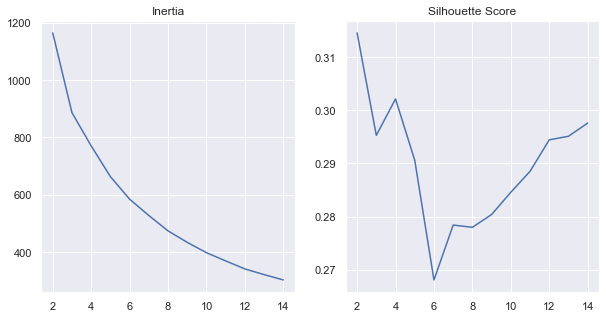

In [302]:
fig, ax = plt.subplots(1,2, figsize=(10,5))
ax[0].plot(pd.Series(inertia,index=range(2,15)))
ax[0].set_title('Inertia') 
ax[1].plot(pd.Series(silhouette,index=range(2,15)))
ax[1].set_title('Silhouette Score')
plt.show()

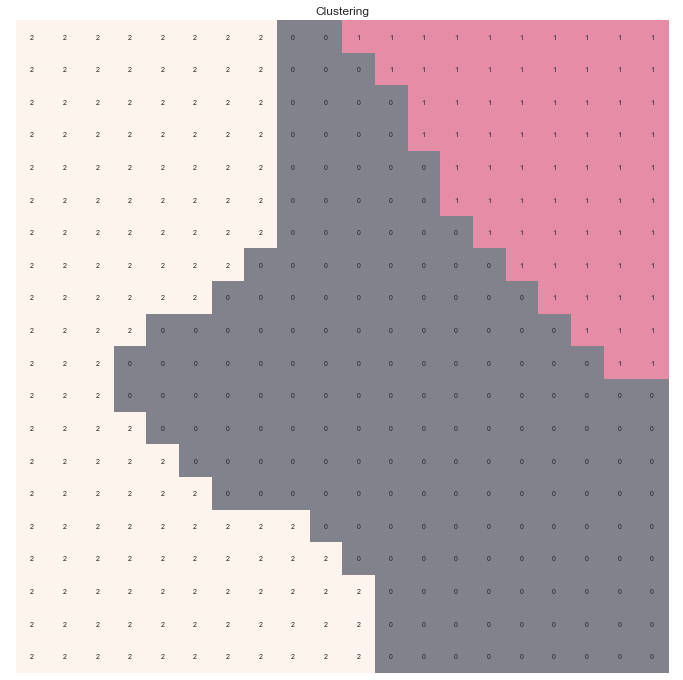

In [303]:
kmeans = KMeans(n_clusters=3, init='k-means++', n_init=20, random_state=10)
nodeclust_labels = kmeans.fit_predict(sm.codebook.matrix)
sm.cluster_labels = nodeclust_labels  

hits = HitMapView(12, 12,"Clustering", text_size=10)
hits.show(sm, anotate=True, onlyzeros=False, labelsize=7, cmap="Pastel1")

plt.show()

In [304]:
neurons=pd.DataFrame(data=sm.codebook.matrix,columns=df_behavioral.columns)   #saving the labels
neurons['Final Cluster']=sm.cluster_labels

In [305]:
#mapper between initial and final clusters
cluster_mapper = neurons['Final Cluster'].to_dict()

#mapping the final clusters on the centroids to the observations
df_ksom_behavioral['Final Cluster'] = df_ksom_behavioral.apply(
    lambda row: cluster_mapper[(row['Initial Cluster'])], axis=1)

df_ksom_behavioral.drop('Initial Cluster', axis=1, inplace=True)

In [306]:
df_ksom_behavioral.groupby('Final Cluster').mean()

,CustValYear,PremMotor,PremHousehold,PremHealth,PremLife,PremWork
Final Cluster,,,,,,
0,-0.188902,-0.488569,0.028207,0.737065,0.161299,0.113829
1,0.521182,-1.316222,1.489007,0.046436,1.274230,1.406354
2,-0.005213,0.949765,-0.568222,-0.721444,-0.592973,-0.600612


In [307]:
#computing the R^2 of the cluster solution
sst = get_ss(df_behavioral)  #get total sum of squares
ssw_labels = df_ksom_behavioral.groupby(by='Final Cluster').apply(get_ss)  #compute ssw for each cluster labels
ssb = sst - np.sum(ssw_labels)  
r2 = ssb / sst
print("Cluster solution with R^2 of %0.4f" % r2)

Cluster solution with R^2 of 0.4510


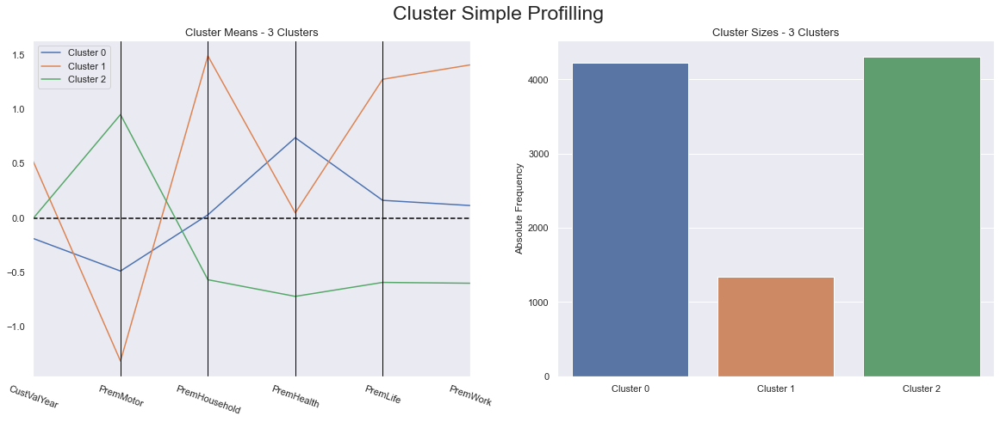

In [308]:
cluster_profiles(df_ksom_behavioral, ['Final Cluster'], (20,7))

<a class="anchor" id="hcsom">

### 2.5 Self-organizing Map and Hierarchical Clustering
</a>

In [309]:
np.random.seed(10)  #rectangular lattice led to a lower quantization error

sm = sompy.SOMFactory().build(
    df_behavioral.values, 
    mapsize=[20, 20],  
    initialization='random', 
    neighborhood='gaussian',
    training='batch',
    lattice='rect',
    component_names=df_behavioral.columns
)
sm.train(n_job=4, verbose='info', train_rough_len=100, train_finetune_len=100)

 Training...
 random_initialization took: 0.000000 seconds
 Rough training...
 radius_ini: 7.000000 , radius_final: 1.166667, trainlen: 100

 epoch: 1 ---> elapsed time:  0.042000, quantization error: 1.730492

 epoch: 2 ---> elapsed time:  0.043000, quantization error: 1.913958

 epoch: 3 ---> elapsed time:  0.043000, quantization error: 1.454205

 epoch: 4 ---> elapsed time:  0.041000, quantization error: 1.399637

 epoch: 5 ---> elapsed time:  0.042000, quantization error: 1.374461

 epoch: 6 ---> elapsed time:  0.042000, quantization error: 1.364897

 epoch: 7 ---> elapsed time:  0.042000, quantization error: 1.357664

 epoch: 8 ---> elapsed time:  0.043000, quantization error: 1.350832

 epoch: 9 ---> elapsed time:  0.041000, quantization error: 1.344399

 epoch: 10 ---> elapsed time:  0.045000, quantization error: 1.338354

 epoch: 11 ---> elapsed time:  0.043000, quantization error: 1.332592

 epoch: 12 ---> elapsed time:  0.042000, quantization error: 1.327025

 epoch: 13 ---> 

 epoch: 14 ---> elapsed time:  0.044000, quantization error: 0.818729

 epoch: 15 ---> elapsed time:  0.044000, quantization error: 0.817715

 epoch: 16 ---> elapsed time:  0.043000, quantization error: 0.816528

 epoch: 17 ---> elapsed time:  0.044000, quantization error: 0.815389

 epoch: 18 ---> elapsed time:  0.051000, quantization error: 0.814315

 epoch: 19 ---> elapsed time:  0.052000, quantization error: 0.813199

 epoch: 20 ---> elapsed time:  0.047000, quantization error: 0.811997

 epoch: 21 ---> elapsed time:  0.047000, quantization error: 0.810600

 epoch: 22 ---> elapsed time:  0.045000, quantization error: 0.809240

 epoch: 23 ---> elapsed time:  0.042000, quantization error: 0.807962

 epoch: 24 ---> elapsed time:  0.042000, quantization error: 0.806673

 epoch: 25 ---> elapsed time:  0.044000, quantization error: 0.805428

 epoch: 26 ---> elapsed time:  0.044000, quantization error: 0.804265

 epoch: 27 ---> elapsed time:  0.047000, quantization error: 0.803083

 epoch

In [310]:
hcsom_labels=sm.find_bmu(df_behavioral)[0]
df_hcsom_behavioral = pd.concat((df_behavioral, pd.DataFrame(hcsom_labels,index = df_behavioral.index).rename(columns = {0:'Initial Cluster'})), axis = 1)

In [312]:
#setting distance_threshold=0 and n_clusters=None ensures we compute the full tree
linkage = 'ward'
distance='euclidean'
hclust = AgglomerativeClustering(linkage=linkage, distance_threshold=0, n_clusters=None)
hclust.fit_predict(sm.codebook.matrix)

array([364, 307, 340, 347, 350, 325, 296, 275, 251, 236, 234, 237, 233,
       397, 337, 327, 359, 387, 365, 329, 257, 353, 293, 252, 204, 335,
       245, 232, 261, 323, 373, 116, 235, 395, 389, 263, 303, 219, 355,
       331, 371, 290, 271, 339, 336, 330, 266, 291, 249, 243, 319, 208,
       345, 313, 348, 309, 267, 239, 341, 221, 378, 306, 351, 280, 377,
       300, 314, 253, 212, 125, 326, 213, 343, 375, 229, 349, 173, 383,
       201, 308, 384, 238, 262, 376, 315, 223, 264, 153, 278, 167, 310,
       269, 230, 202, 305, 311, 295, 265, 222, 361, 382, 273, 242, 362,
       367, 366, 182, 363, 356, 324, 388, 226, 207, 360, 277, 270, 154,
       312, 181, 217, 379, 174, 344, 255, 218, 368, 244, 285, 231, 279,
       228, 281, 381, 328, 317, 118, 289, 276, 171, 203, 374, 132, 346,
       318, 172, 215, 260, 177, 294, 155, 103, 216, 220, 107, 283, 187,
       211, 225, 372, 380, 179, 385, 156, 354, 334,  85, 333, 105, 214,
       162, 369, 352, 272, 169, 224, 287, 321, 241, 399, 338,  8

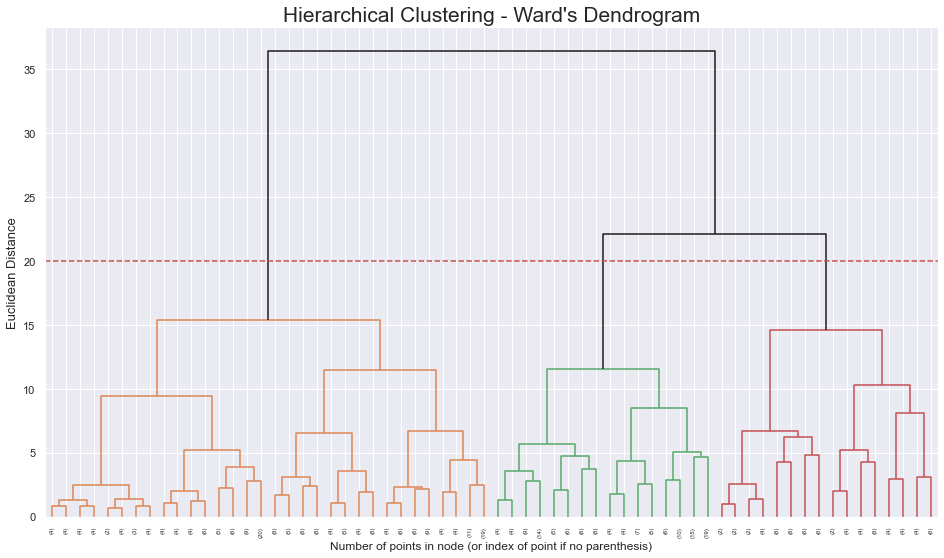

In [313]:
#create the counts of samples under each node (number of points being merged)
counts = np.zeros(hclust.children_.shape[0])
n_samples = len(hclust.labels_)

#hclust.children_ contains the observation ids that are being merged together
#at the i-th iteration, children[i][0] and children[i][1] are merged to form node n_samples + i
for i, merge in enumerate(hclust.children_):
    #track the number of observations in the current cluster being formed
    current_count = 0
    for child_idx in merge:
        if child_idx < n_samples:
            #if this is True, then we are merging an observation
            current_count += 1  # leaf node
        else:
            #otherwise, we are merging a previously formed cluster
            current_count += counts[child_idx - n_samples]
    counts[i] = current_count

#the hclust.children_ is used to indicate the two points/clusters being merged (dendrogram's u-joins)
#the hclust.distances_ indicates the distance between the two points/clusters (height of the u-joins)
#the counts indicate the number of points being merged (dendrogram's x-axis)
linkage_matrix = np.column_stack(
    [hclust.children_, hclust.distances_, counts]
).astype(float)

#plot the corresponding dendrogram
sns.set()
fig = plt.figure(figsize=(16,9))
y_threshold = 20
dendrogram(linkage_matrix, truncate_mode='level', p=5, color_threshold=y_threshold, above_threshold_color='k')
plt.hlines(y_threshold, 0, 1000, colors="r", linestyles="dashed")
plt.title(f'Hierarchical Clustering - {linkage.title()}\'s Dendrogram', fontsize=21)
plt.xlabel('Number of points in node (or index of point if no parenthesis)')
plt.ylabel(f'{distance.title()} Distance', fontsize=13)
plt.show()

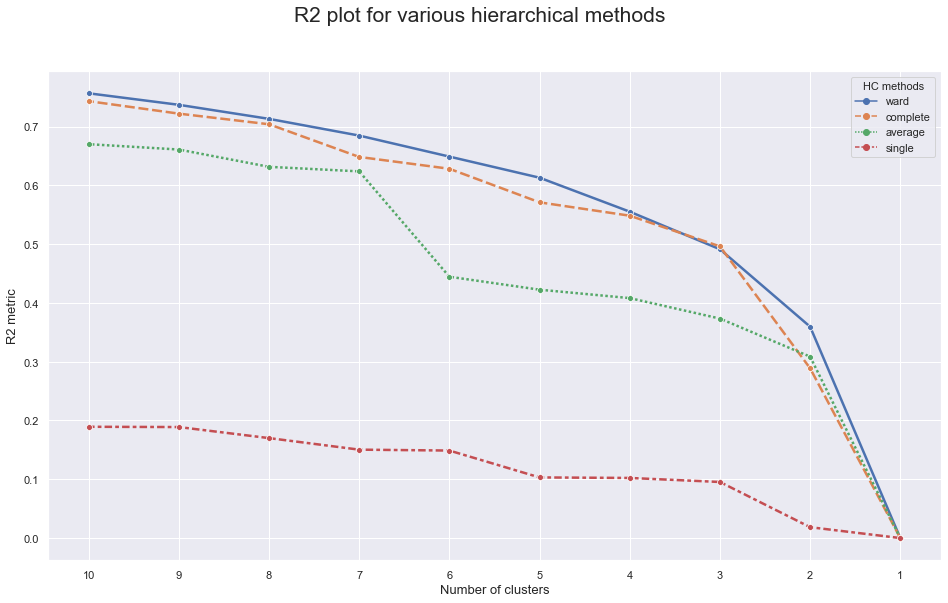

In [314]:
hc_neurons=pd.DataFrame(data=sm.codebook.matrix,columns=df_behavioral.columns)

hc_methods = ["ward", "complete", "average", "single"]
#call function defined above to obtain the R2 statistic for each hc_method
max_nclus = 10
r2_hc_methods = np.vstack(
    [
        get_r2_hc(df=hc_neurons, link_method=link, max_nclus=max_nclus) 
        for link in hc_methods
    ]
).T
r2_hc_methods = pd.DataFrame(r2_hc_methods, index=range(1, max_nclus + 1), columns=hc_methods)

sns.set()
#plot data
fig = plt.figure(figsize=(16,9))
sns.lineplot(data=r2_hc_methods, linewidth=2.5, markers=["o"]*4)

#finalize the plot
fig.suptitle("R2 plot for various hierarchical methods", fontsize=21)
plt.gca().invert_xaxis()  # invert x axis
plt.legend(title="HC methods", title_fontsize=11)
plt.xticks(range(1, max_nclus + 1))
plt.xlabel("Number of clusters", fontsize=13)
plt.ylabel("R2 metric", fontsize=13)

plt.show()

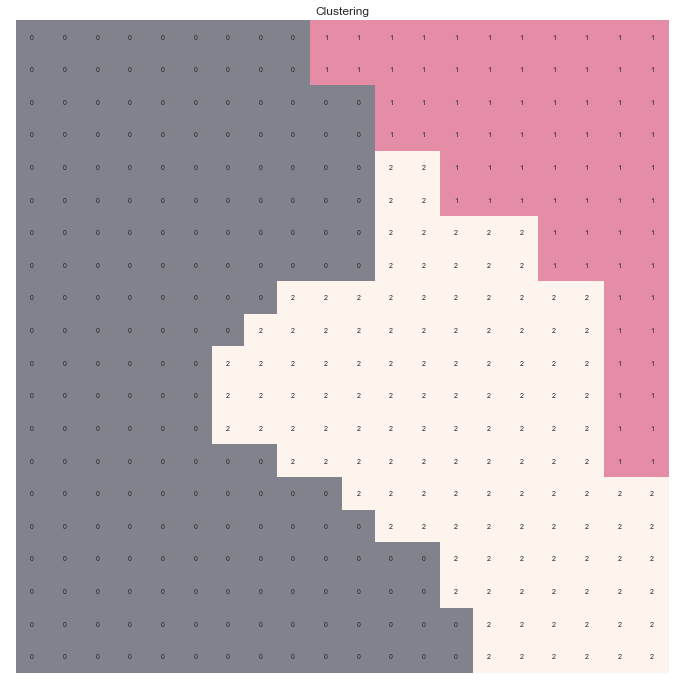

In [315]:
hierclust = AgglomerativeClustering(n_clusters=3, linkage='ward')
nodeclust_labels = hierclust.fit_predict(sm.codebook.matrix)
sm.cluster_labels = nodeclust_labels 

hits  = HitMapView(12, 12,"Clustering",text_size=10)
hits.show(sm, anotate=True, onlyzeros=False, labelsize=7, cmap="Pastel1")

plt.show()

In [316]:
neurons['Final Cluster']=sm.cluster_labels    #saving the labels

In [317]:
#mapper between initial and final clusters
cluster_mapper = neurons['Final Cluster'].to_dict()

#mapping the final clusters on the centroids to the observations
df_hcsom_behavioral['Final Cluster'] = df_hcsom_behavioral.apply(
    lambda row: cluster_mapper[(row['Initial Cluster'])], axis=1)

df_hcsom_behavioral.drop('Initial Cluster', axis=1, inplace=True)

In [318]:
df_hcsom_behavioral.groupby('Final Cluster').mean()

,CustValYear,PremMotor,PremHousehold,PremHealth,PremLife,PremWork
Final Cluster,,,,,,
0,-0.021435,0.719938,-0.463904,-0.468096,-0.485453,-0.516891
1,0.529955,-1.232049,1.437899,0.051273,1.342144,1.096773
2,-0.283774,-0.696040,0.045818,0.939100,0.200443,0.374859


In [319]:
#computing the R^2 of the cluster solution
sst = get_ss(df_behavioral)  #get total sum of squares
ssw_labels = df_hcsom_behavioral.groupby(by='Final Cluster').apply(get_ss)  #compute ssw for each cluster labels
ssb = sst - np.sum(ssw_labels)  
r2 = ssb / sst
print("Cluster solution with R^2 of %0.4f" % r2)

Cluster solution with R^2 of 0.4184


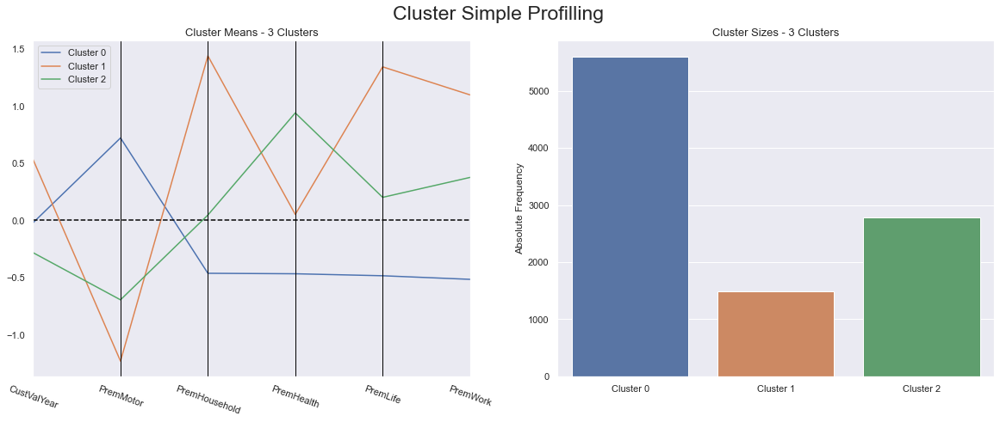

In [320]:
cluster_profiles(df_hcsom_behavioral, ['Final Cluster'], (20,7))

<a class="anchor" id="merge">

# Merging the Perspectives
</a>

In [321]:
df_final=df_standard.copy()

In [322]:
df_final_notscaled=df_standard.copy()
scaled_feat=final_scaler.inverse_transform(df_final_notscaled[metric_features])  #reverse the scale to better interpret the data
df_final_notscaled[metric_features]=scaled_feat

In [323]:
#not interesting to analyze
df_final.drop(columns=['GeoLivArea'],inplace=True)
df_final_notscaled.drop(columns=['GeoLivArea'],inplace=True)

In [324]:
#features that were not used for clustering
metric_features.remove('CustMonVal')
metric_features.remove('ClaimsRate')
metric_features.remove('YearsCustomer')
non_metric_features.remove('GeoLivArea')

In [325]:
df_final['Demographic Cluster']=df_ksom_behavioral['Final Cluster']
df_final['Behavioral Cluster']=df_prot_demo['Cluster (with 3 in total)']
demographic_centroids=df_final.groupby(['Demographic Cluster', 'Behavioral Cluster'])[non_metric_features].agg(pd.Series.mode)
behavioral_centroids=df_final.groupby(['Demographic Cluster', 'Behavioral Cluster'])[metric_features].mean()
initial_centroids=pd.concat([demographic_centroids,behavioral_centroids],axis=1)  #concatenate the centroids from the two perspectives

In [326]:
#choose optimal K using Elbow method
cost = []

for n_clus in range(1,7):  #iterate over desired ncluster range
    kproto = KPrototypes(n_clusters= n_clus, init='Huang',n_jobs = 1, random_state= 10)
    clusters = kproto.fit_predict(initial_centroids, categorical=[0,1,2,3])
    cost.append(kproto.cost_)  #save the inertia of the given cluster solution
    print('Cost', n_clus, 'clusters =', kproto.cost_)

Cost 1 clusters = 37.50452934705108
Cost 2 clusters = 19.348538842621643
Cost 3 clusters = 11.68130290849267
Cost 4 clusters = 8.522094392066672
Cost 5 clusters = 6.079776505164602
Cost 6 clusters = 3.8372748527272744


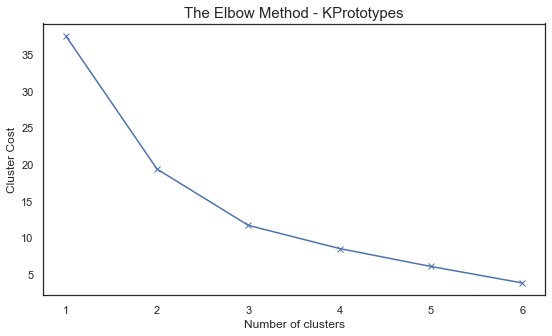

In [327]:
sns.set_style("white")
range_K=range(1,7)
plt.figure(figsize=(9,5))
plt.plot(range_K, cost, 'bx-')
pd.Series(cost,index=range_K)
plt.xlabel('Number of clusters')
plt.ylabel('Cluster Cost')
plt.title('The Elbow Method - KPrototypes', size=15)
plt.show()

In [328]:
kprot = KPrototypes(n_jobs=1, n_clusters = 6, init = 'Huang', random_state=10)  #we decided to use 6 clusters
kprot_labels = kprot.fit_predict(initial_centroids, categorical = [0,1,2,3])
final_centroids = pd.concat((initial_centroids, pd.DataFrame(kprot_labels,index = initial_centroids.index).rename(columns = {0:'Final Cluster'})), axis = 1)

In [329]:
#mapper between initial and final clusters
cluster_mapper = final_centroids['Final Cluster'].to_dict()

#mapping the final clusters on the centroids to the observations
df_final['Final Cluster'] = df_final.apply(
    lambda row: cluster_mapper[(row['Demographic Cluster'],row['Behavioral Cluster'])], axis=1)

df_final.drop(columns=['Demographic Cluster','Behavioral Cluster'], axis=1, inplace=True)

In [330]:
df_final_notscaled['Final Cluster']=df_final['Final Cluster']

In [331]:
df_final['Final Cluster'].value_counts()

4    3375
0    2488
1    1739
3    1026
2     931
5     318
Name: Final Cluster, dtype: int64

In [332]:
df_final.groupby('Final Cluster')[metric_features+["CustMonVal"]+["ClaimsRate"]+["YearsCustomer"]].mean()

,PremMotor,PremHousehold,PremHealth,PremLife,PremWork,CustValYear,AnnualSal,CustMonVal,ClaimsRate,YearsCustomer
Final Cluster,,,,,,,,,,
0,-0.478217,0.037323,0.691224,0.177243,0.134113,-0.178630,-0.638591,-0.169621,0.176397,0.046630
1,-0.503381,0.015165,0.802651,0.138487,0.084808,-0.203599,1.197687,-0.205819,0.213735,0.002697
2,0.771704,-0.510699,-0.506679,-0.515631,-0.540014,0.006479,1.121003,-0.006360,-0.125534,-0.028051
3,-1.380100,1.528988,-0.005471,1.406497,1.530465,0.441911,-1.175310,0.459956,-0.085684,-0.036039
4,0.998883,-0.584089,-0.780688,-0.614308,-0.617328,-0.008438,-0.180489,-0.008962,-0.147730,0.011735
5,-1.110125,1.360011,0.213910,0.847484,1.005923,0.776943,1.126781,0.718830,-0.331478,-0.205556


In [333]:
df_final_notscaled.groupby('Final Cluster')[metric_features+["CustMonVal"]+["ClaimsRate"]+["YearsCustomer"]].mean()

,PremMotor,PremHousehold,PremHealth,PremLife,PremWork,CustValYear,AnnualSal,CustMonVal,ClaimsRate,YearsCustomer
Final Cluster,,,,,,,,,,
0,236.628199,208.600201,220.557089,45.595752,43.738625,5.850140,22866.753589,171.112994,0.740812,30.289623
1,233.215664,203.606901,228.824173,44.016159,41.707102,5.607374,44236.345783,161.639442,0.753427,29.999770
2,406.131933,85.103061,131.681594,17.355854,15.962481,7.649920,43343.935553,213.840806,0.638797,29.796908
3,114.322407,544.747856,168.867492,95.697261,101.272680,11.883553,16620.714365,335.882222,0.652261,29.744200
4,436.940127,68.564652,111.352116,13.333988,12.776916,7.504887,28197.890557,213.159887,0.631298,30.059401
5,150.934151,506.668711,185.143912,72.913208,79.659906,15.140999,43411.172808,403.633333,0.569214,28.625786


In [334]:
df_final.groupby('Final Cluster')[non_metric_features].agg(pd.Series.mode)

,HighSchool,BSc/MSc,PhD,Children
Final Cluster,,,,
0,0.0,0.0,0.0,1.0
1,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,1.0
4,0.0,1.0,0.0,1.0
5,1.0,0.0,0.0,0.0


In [335]:
df_final.groupby('Final Cluster')[non_metric_features].mean()

,HighSchool,BSc/MSc,PhD,Children
Final Cluster,,,,
0,0.392283,0.468650,0.037379,0.888666
1,0.409431,0.446233,0.051754,0.182289
2,0.291085,0.490870,0.187970,0.454350
3,0.452242,0.170565,0.003899,0.791423
4,0.227852,0.634963,0.097481,0.945481
5,0.588050,0.150943,0.009434,0.207547


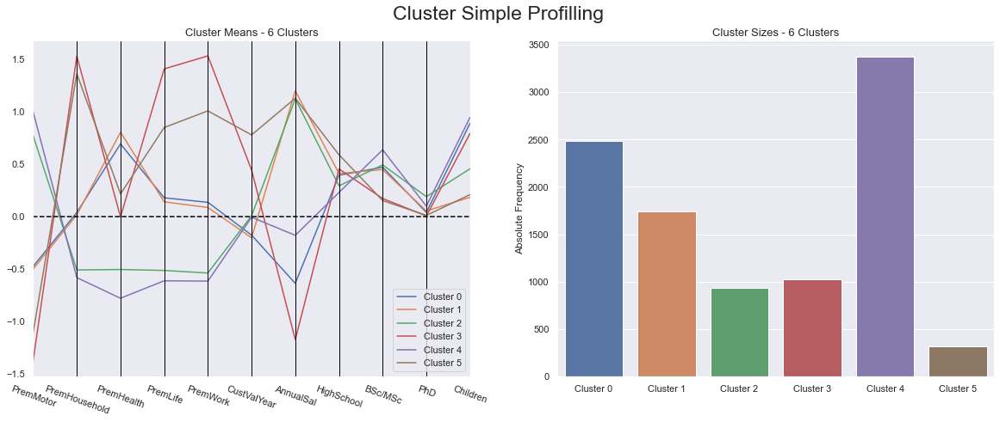

In [336]:
cluster_profiles(df_final[metric_features+non_metric_features+['Final Cluster']], ['Final Cluster'], (20,7))

<a class="anchor" id="tsne">

# Cluster Visualization using t-SNE
</a>

In [337]:
tsne = TSNE(random_state=10).fit_transform(df_final[metric_features])

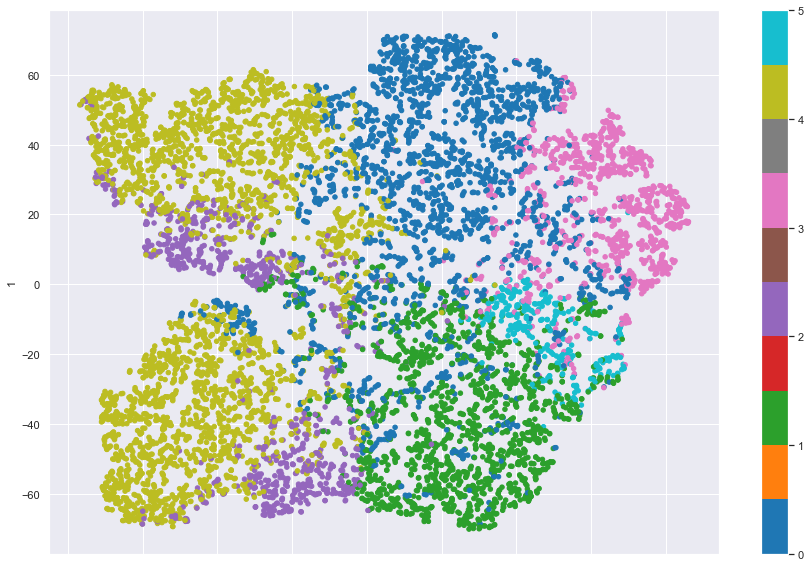

In [338]:
pd.DataFrame(tsne).plot.scatter(x=0, y=1, c=df_final['Final Cluster'], colormap='tab10',figsize=(15,10))
plt.show()

<a class="anchor" id="importanceoutliers">

# Assess Feature Importance and Classify Outliers
</a>

In [329]:
def get_ss_variables(df):
    """Get the SS for each variable
    """
    ss_vars = df.var() * (df.count() - 1)
    return ss_vars

def r2_variables(df, labels):
    """Get the R² for each variable
    """
    sst_vars = get_ss_variables(df)
    ssw_vars = np.sum(df.groupby(labels).apply(get_ss_variables))
    return 1 - ssw_vars/sst_vars

In [330]:
r2_variables(df_final[metric_features + ['Final Cluster']], 'Final Cluster').drop('Final Cluster')

PremMotor        0.760453
PremHousehold    0.507534
PremHealth       0.466915
PremLife         0.413987
PremWork         0.472563
CustValYear      0.066783
AnnualSal        0.676517
dtype: float64

<a class="anchor" id="dt">

### 1. Decision Tree Classifier
</a>

In [331]:
#preparing the data
x = df_final.drop(columns=['Final Cluster','CustMonVal','ClaimsRate','YearsCustomer'])
y = df_final['Final Cluster']

#splitting the data
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.3, random_state=10)

#fitting the decision tree
dt = DecisionTreeClassifier(random_state=10, max_depth=4)
dt.fit(x_train, y_train)
print("It is estimated that in average, we are able to predict {0:.2f}% of the customers correctly".format(dt.score(x_test, y_test)*100))

It is estimated that in average, we are able to predict 86.10% of the customers correctly


In [332]:
#assessing feature importance
pd.Series(dt.feature_importances_, index=x_train.columns)

Children         0.002165
PremMotor        0.379037
PremHousehold    0.117101
PremHealth       0.000000
PremLife         0.000000
PremWork         0.050607
HighSchool       0.000000
BSc/MSc          0.024397
PhD              0.000000
CustValYear      0.000000
AnnualSal        0.426693
dtype: float64

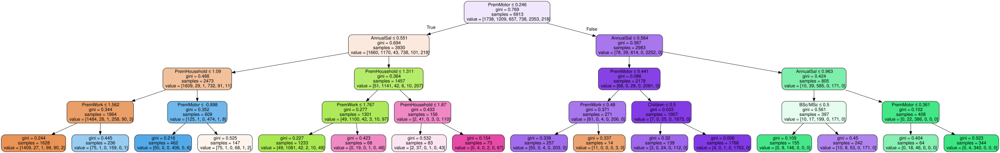

In [333]:
#visualizing the decision tree
dt_graph = export_graphviz(dt, out_file=None, 
                           feature_names=x.columns.to_list(),
                           filled=True,
                           rounded=True,
                           special_characters=True)  
graphviz.Source(dt_graph)

<a class="anchor" id="knn">

### 2. K-nearest Neighbors Classifier
</a>

In [334]:
knn = KNeighborsClassifier(n_neighbors=6)   #fitting knn
knn.fit(x_train[metric_features], y_train)
print("It is estimated that in average, we are able to predict {0:.2f}% of the customers correctly".format(knn.score(x_test[metric_features], y_test)*100))

It is estimated that in average, we are able to predict 87.89% of the customers correctly


In [335]:
#join the two outlier datasets (corresponding to the 2 times we removed outliers)
#so to join we had to alter them so that they have the same features and the same scaling method 
#then to predict the cluster labels we guaranteed that they have the necessary features and dropped unnecessary ones
#we decided to use knn for the prediction because of the better mean accuracy
df_out['YearsCustomer']=2016-df_out['FirstPolYear']
df_out['CustValYear']=df_out['CustMonVal']/df_out['YearsCustomer']
df_out['AnnualSal']=df_out['MonthSal']*12
df_out.drop(columns=['FirstPolYear','MonthSal','GeoLivArea'],inplace=True)
scaled_feat = final_scaler.transform(df_out[['CustMonVal', 'ClaimsRate', 'PremMotor', 'PremHousehold',
       'PremHealth', 'PremLife', 'PremWork','YearsCustomer', 'CustValYear', 'AnnualSal']])
df_out[metric_features+["CustMonVal"]+["ClaimsRate"]+["YearsCustomer"]] = scaled_feat
df_out.drop(columns=['CustMonVal','ClaimsRate',"YearsCustomer"],inplace=True)

In [336]:
df_out_2.drop(columns=['GeoLivArea','CustMonVal',"ClaimsRate","YearsCustomer"],inplace=True)

In [337]:
df_out=pd.concat([df_out,df_out_2],axis=0)

In [338]:
#predicting the cluster labels of the outliers
df_out['Final Cluster'] = knn.predict(df_out[metric_features])
df_out.head()

,Children,PremMotor,PremHousehold,PremHealth,PremLife,PremWork,HighSchool,BSc/MSc,PhD,CustValYear,AnnualSal,Final Cluster
CustID,,,,,,,,,,,,
14,1.0,-1.110468,1.121093,-1.896150,0.633060,-0.560479,0.0,0.0,0.0,5.632518,1.365121,5
52,1.0,-57.045374,73.041372,1.887449,-0.799596,-1.883117,0.0,1.0,0.0,-0.818785,-1.145854,3
113,1.0,-34.138556,44.302857,1.598979,-0.868600,-1.528095,0.0,0.0,1.0,-0.846019,-0.663124,3
136,1.0,-39.793082,41.787127,-0.028537,-0.165917,-0.349272,0.0,1.0,0.0,2.406867,-1.000234,3
150,1.0,0.153621,-0.151571,-1.744540,-0.013044,-1.883117,0.0,0.0,0.0,-0.486087,10.031213,2
